In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from typing import Tuple
from tqdm import tqdm
import pandas as pd
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)


%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

ruta_scripts = Path.cwd().parent / "scripts"
sys.path.append(str(ruta_scripts))

import Modelos_neuronales as mn

In [2]:
import jpype
import os
from jpype import JClass
jar_path = os.path.abspath("infodynamics.jar")
jpype.startJVM(classpath=[jar_path])
TECalcClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").TransferEntropyCalculatorKraskov
teCalc = TECalcClass()
from jpype import JPackage
CTEClass = JPackage("infodynamics.measures.continuous.kraskov").ConditionalTransferEntropyCalculatorKraskov
cteCalc = CTEClass()
MIClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").MutualInfoCalculatorMultiVariateKraskov1
miCalc = MIClass()


from sklearn.feature_selection import mutual_info_regression

## Ajuste del hiperparámetro número de vecinos del algoritmo KSG

En este notebook, el estudio se centra en determinar el valor o rango de valores del hiperparámetro "número de vecinos ($k$)" que producen estimaciones mediante el algoritmo KSG más robustas. Se estudaiará por separado el caso de la IM y la TE, con el ánimo de obtener resultados similares. En ambos casos se considera una primera aproximación teórica sobre modelos lineales con ruido gaussiano, usado a modo de ground truth. Una vez creada una primera intuición de esa manera, se comprueba el efecto del hiperparámetro sobre datos de naturaleza neuronal (simulados). 

### Estimador de Información Mutua

El estimador `mutual_info_regression` de scikit-learn permite modificar el valor del hiperparámetro a través de `n_neighbors`. 

#### Modelo Teórico (Modelo lineal)

Suponiendo el modelo: $x = y + \varepsilon$, donde:

* $y \sim \mathcal{N}(0, \sigma_y^2)$
* $\varepsilon \sim \mathcal{N}(0, \sigma_\varepsilon^2)$, independiente de $y$,

entonces $x$ también es gaussiana y el par $(x, y)$ es conjuntamente gaussiano. La información mutua entre ambas variables en este escenario concreto presenta una fórmula explícita:

$$I(x;y) = \frac{1}{2} \log\left(1 + \frac{\sigma_y^2}{\sigma_\varepsilon^2}\right)$$

Comenzamos con un análisis del estimador analizando como se detecta la cantidad de IM según varía la cantidad de ruido en el sistema (es decir $\sigma_{\epsilon}^{2}$). Todo ello, a su vez, para diferentes valores del hiperparámetro `n_neighbors`.

Con el fin de evaluar la robustez estadística del estimador frente a la estocasticidad de las muestras, el procedimiento se repite durante $n_{\text{runs}} = 20$ ejecuciones independientes utilizando $n_{\text{samples}} = 400$ observaciones en cada iteración. Los resultados se visualizan mediante una rejilla de gráficos donde se contrasta la curva de Información Mutua teórica frente a la media empírica obtenida por el algoritmo KSG. Adicionalmente, el área sombreada en torno a la media representa la desviación estándar empírada (media muestral $\pm$ std) calculada a lo largo de las ejecuciones, permitiendo analizar de manera conjunta el sesgo y la varianza del estimador en función de la complejidad local del vecindario ($k$) y la intensidad del ruido en el sistema.


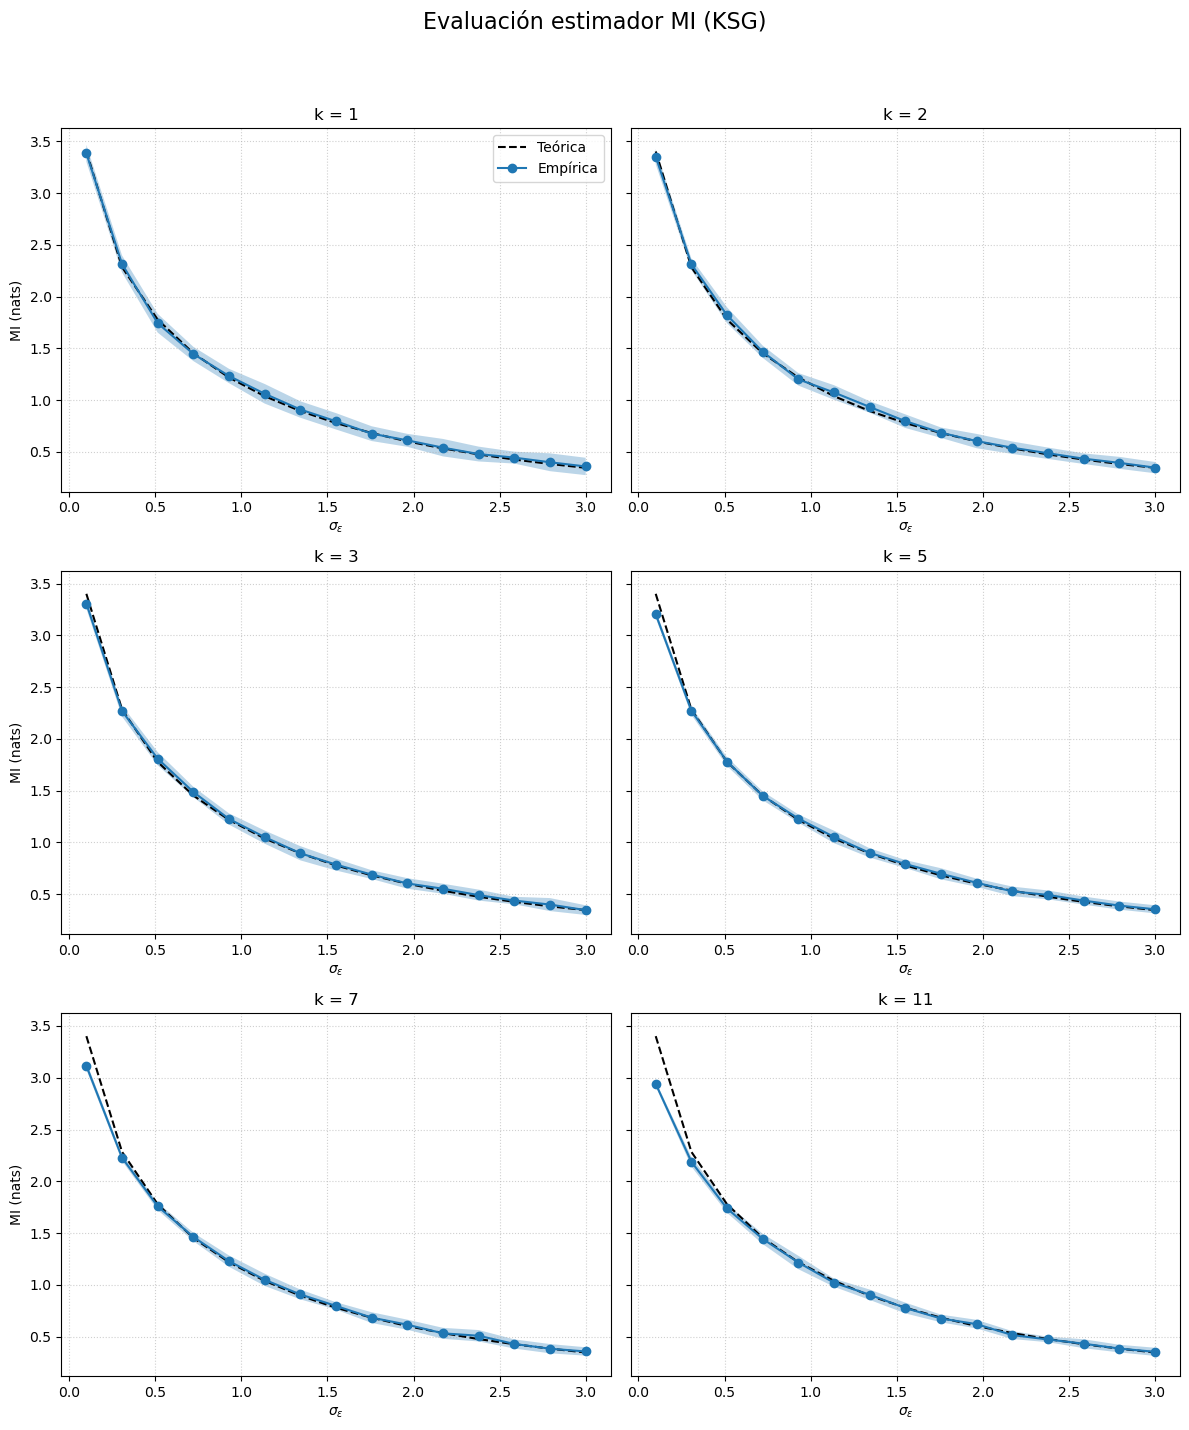

In [15]:
n_samples = 400
n_runs = 20
sigma_y = 3.0
sigma_eps_values = np.linspace(0.1, 3.0, 15)

fig, axes = plt.subplots(3, 2, figsize=(12, 15), sharey=True)
axes_flat = axes.flatten()

mi_emp_all = np.zeros((n_runs, len(sigma_eps_values)))
mi_theo = np.zeros(len(sigma_eps_values))

neighbors_list = [1, 2, 3, 5, 7, 11]

for idx, n_neighbors in enumerate(neighbors_list):
    
    ax = axes_flat[idx]
    mi_emp_all = np.zeros((n_runs, len(sigma_eps_values)))
    
    for j, sigma_eps in enumerate(sigma_eps_values):
        
        # MI teórica
        mi_theo[j] = 0.5 * np.log(1 + sigma_y**2 / sigma_eps**2)
        
        for run in range(n_runs):
            Y = np.random.normal(0, sigma_y, n_samples)
            eps = np.random.normal(0, sigma_eps, n_samples)
            X = Y + eps
            
            mi = mutual_info_regression(Y.reshape(-1, 1), X, n_neighbors=n_neighbors, discrete_features=False)
            mi_emp_all[run, j] = mi[0]

    mi_emp_mean = np.mean(mi_emp_all, axis=0)
    mi_emp_std  = np.std(mi_emp_all, axis=0)

    # Plot
    ax.plot(sigma_eps_values, mi_theo, 'k--', label="Teórica")
    ax.plot(sigma_eps_values, mi_emp_mean, 'o-', label="Empírica")
    ax.fill_between(
        sigma_eps_values,
        mi_emp_mean - mi_emp_std,
        mi_emp_mean + mi_emp_std,
        alpha=0.3
    )

    ax.set_title(f"k = {n_neighbors}")
    ax.set_xlabel(r"$\sigma_\epsilon$")
    ax.grid(True, linestyle=':', alpha=0.6)

for i in range(3):
    axes[i, 0].set_ylabel("MI (nats)")

axes_flat[0].legend()

plt.suptitle("Evaluación estimador MI (KSG)", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Los resultados siguen un patrón que se podía esperar intuitivamente. En términos generales, respecto al valor del hiperparámetro `n_neighbors`, los valores más pequeños se asocian con resultados de varianza grande y poco sesgo, mientras que valores más altos se asocian con resultados de menor varianza pero mayor sesgo. Además, como era de esperar, la varianza de las estimaciones es progresivamente más grande según aumenta la cantidad de ruido en el sistema (modelada mediante $\sigma_{\epsilon}^2$), a la vez que la cantidad de IM estimada decrece en esa dirección. Se observa a su vez un fenómeno no tan intuitivo a priori: el sesgo de las estimaciones es mayor cuando el ruido es pequeño, es decir, cuando el valor de la IM es más grande (a partir de IM$=2$ nats). 

Parece especialmente interesante analizar el comportamiento para un valor fijo de $\sigma_{\epsilon}^2$ donde haya un equilibrio entre sesgo y varianza. Por ejemplo $\sigma_{\epsilon}^2 = 0.4$ genera un equilibrio entre estimaciones con sesgo para `n_neighbors` grande y varianza notable para `n_neighbors` pequeño.

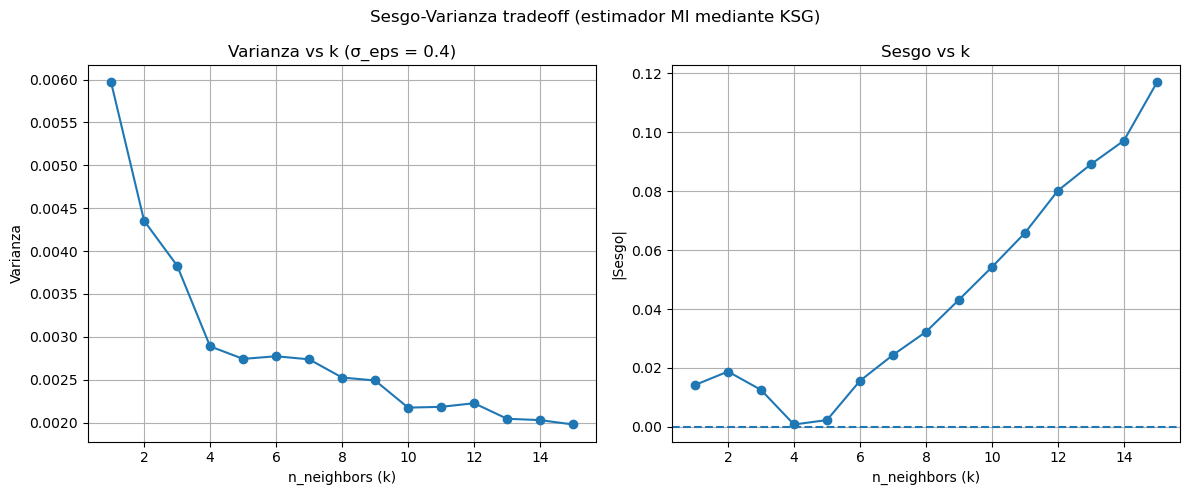

In [16]:
n_samples = 400
n_runs = 500
sigma_y = 3.0
sigma_eps_fixed = 0.4 
neighbors_list = np.arange(1, 16)

var_k = []
mean_k = []

for n_neighbors in neighbors_list:
    
    mi_runs = []
    
    for run in range(n_runs):
        Y = np.random.normal(0, sigma_y, n_samples)
        eps = np.random.normal(0, sigma_eps_fixed, n_samples)
        X = Y + eps

        mi = mutual_info_regression(Y.reshape(-1, 1), X, n_neighbors=n_neighbors, discrete_features=False)
        mi_runs.append(mi[0])
    
    mi_runs = np.array(mi_runs)
    
    mean_k.append(np.mean(mi_runs))
    var_k.append(np.var(mi_runs))

# valor teórico
mi_theo = 0.5 * np.log(1 + sigma_y**2 / sigma_eps_fixed**2)
bias_k = np.array(mean_k) - mi_theo

# ======================
# PLOT
# ======================

fig, axes = plt.subplots(1, 2, figsize=(12,5))

# --- VARIANZA ---
axes[0].plot(neighbors_list, var_k, 'o-')
axes[0].set_xlabel("n_neighbors (k)")
axes[0].set_ylabel("Varianza")
axes[0].set_title(f"Varianza vs k (σ_eps = {sigma_eps_fixed})")
axes[0].grid(True)

# --- SESGO ---
axes[1].plot(neighbors_list, np.abs(bias_k), 'o-')
axes[1].axhline(0, linestyle='--') 
axes[1].set_xlabel("n_neighbors (k)")
axes[1].set_ylabel("|Sesgo|")
axes[1].set_title("Sesgo vs k")
axes[1].grid(True)

plt.suptitle("Sesgo-Varianza tradeoff (estimador MI mediante KSG)")
plt.tight_layout()
plt.show()

Los resultados son muy significativos. Se pone de manifiesto el comportamiento que ya se había intuido con el primer análisis general. La gráfica de la izquierda muestra una disminución progresiva de la varianza a medida que aumenta el número de vecinos $k$. Para valores pequeños de $k$ el cálculo depende excesivamente de las distancias a los vecinos más próximos, haciéndolo muy sensible a fluctuaciones locales o ruido muestral. A medida que $k$ crece, el vecindario abarca una región más amplia, lo que actúa como un efecto de suavizado estadístico que estabiliza las estimaciones.

La gráfica de la derecha muestra un comportamiento opuesto; el valor absoluto del sesgo aumenta de forma casi lineal y sostenida a medida que incrementamos $k$. Al aumentar $k$ el sesgo se dispara debido a que un vecindario excesivamente grande promedia la densidad de probabilidad sobre una región demasiado amplia, alejando el valor esperado del estimador del valor teórico real. 

A continuación se cuantifica el error de estimación evaluando el compromiso entre sesgo y varianza para cada número de vecinos analizado. Se calcula el Error Cuadrático Medio (MSE) como la suma de la varianza y el cuadrado del sesgo. Finalmente se identifica de forma automatizada el hiperparámetro $k$ óptimo que minimiza dicho error.

k óptimo = 4 en función de MSE


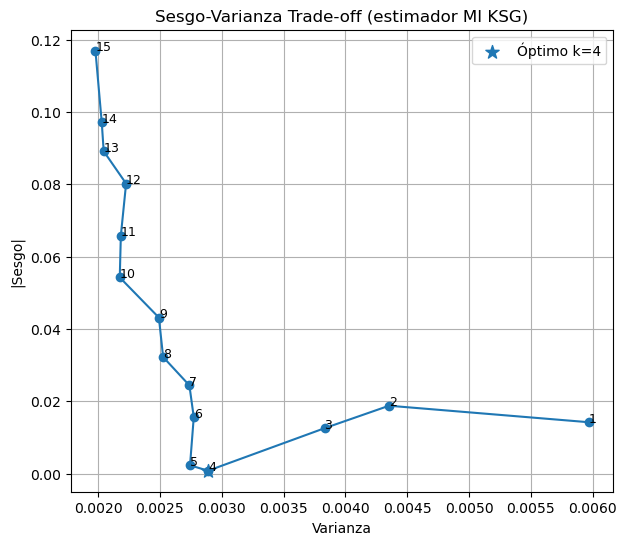

In [17]:
# valor teórico
mi_theo_fixed = 0.5 * np.log(1 + sigma_y**2 / sigma_eps_fixed**2)

mean_k = np.array(mean_k)
var_k  = np.array(var_k)

bias_k = mean_k - mi_theo_fixed
abs_bias_k = np.abs(bias_k)

# Error cuadrático medio (MSE)
error_k = var_k + bias_k**2

# k óptimo
k_opt = neighbors_list[np.argmin(error_k)]
print(f"k óptimo = {k_opt} en función de MSE")

# ======================
# PLOT bias vs var
# ======================

plt.figure(figsize=(7,6))

plt.plot(var_k, abs_bias_k, 'o-')

for i, k in enumerate(neighbors_list):
    plt.text(var_k[i], abs_bias_k[i], str(k), fontsize=9)

idx_opt = np.argmin(error_k)
plt.scatter(var_k[idx_opt], abs_bias_k[idx_opt], s=100, marker='*', label=f"Óptimo k={k_opt}")

plt.xlabel("Varianza")
plt.ylabel("|Sesgo|")
plt.title("Sesgo-Varianza Trade-off (estimador MI KSG)")
plt.grid(True)
plt.legend()

plt.show()

Los resultados reflejan el clásico dilema del balance entre sesgo y varianza en el aprendizaje automático y la estadística no paramétrica. El punto de equilibrio ideal para este sistema se sitúa en valores intermedios de $k$ (entre $3$ y $5$), donde se logra contener la varianza sin incurrir en un sesgo excesivo.

#### Modelo Práctico (Simulación 2 neuronas)

Con la intuición generada mediante el anterior análisis, es momento de evaluar la influencia del hiperparámetro sobre datos simulados de caracter neuronal. Se uasará el siguiente modelo (neurona 1 (V1) --> neurona 2 (V2)):

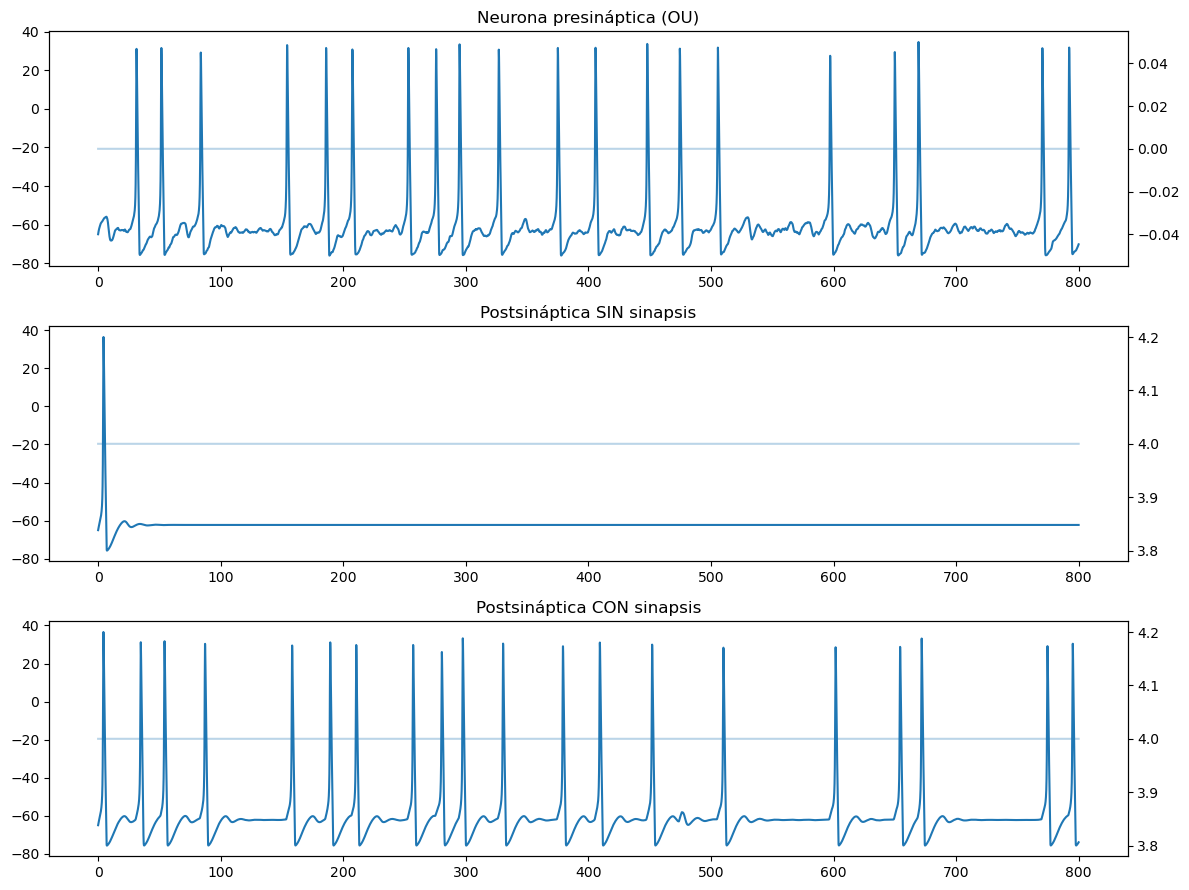

In [14]:
g_syn = 2.5
tau = 0.0    #tau = 1.0 --> 0.1 segundos --> 100 ms
$
# TE 2. Simulación sin ruido (activación de la neurona 1 con sinapsis del entorno)
V1, V2 = mn.hh_multirate(T=800, theta1=0.0, sigma1=0.0, theta2=0.0, sigma2=0.0, cte1=0.0, cte2=4.0, g_syn=g_syn, tau=tau, std_e=0.03, std_i=0.006, ge0=0.05, gi0=0.006, use_OU_I1=False, use_OU_I2=False, plot=True)

En este caso, antes realizar análisis como los anteriores, es fundamental buscar el retardo causal óptimo, para evaluar el estimador de IM con ese delay aplicado a las series temporales (tal y como se argumenta en el notebook "Retardos Causales"). 

In [4]:
def find_optimal_tau_MI(V1, V2, n_vecinos, dt=0.01, max_lags=600, milisegundos = True, plot=False):
    """
    Calcula la Información Mutua para diferentes retardos (tau). El retardo consiste en desplazar V2 respecto a V1.
    """
    
    lags = np.arange(0, max_lags)
    mi_results = []
    factor=5 

    v1_fixed = V1[:-(max_lags)]
    
    for lag in tqdm(lags, desc="Análisis de Tau", unit="lag"):
        v2_shifted = V2[lag : lag + len(v1_fixed)]
        
        mi = mutual_info_regression(v1_fixed[::factor].reshape(-1, 1), v2_shifted[::factor], n_neighbors= n_vecinos, discrete_features=False)
        mi_results.append(mi[0])
        
    mi_results = np.array(mi_results)
    
    # Encontrar el óptimo
    optimal_idx = np.argmax(mi_results)
    optimal_tau = lags[optimal_idx]

    if milisegundos:
        x_values = lags * dt
        optimal_tau = optimal_tau *dt
        xlabel = r"$\tau$ (ms)"
    else:
        x_values = lags
        xlabel = r"$\tau$ (pasos)"

    # Gráfica
    if plot:

        plt.figure(figsize=(10, 6))
        plt.plot(x_values, mi_results, lw=2, label="Información mutua")
        plt.scatter(x_values[optimal_idx], mi_results[optimal_idx], marker="*", s=250, zorder=5, label=f"Óptimo: τ={optimal_tau:.3f}")
        plt.axvline( x_values[optimal_idx], linestyle="--", alpha=0.7)
        plt.xlabel(xlabel)
        plt.ylabel("Mutual Information")
        plt.title(
            f"MI vs τ (k={n_vecinos})"
        )
        plt.grid(True)
        plt.legend()
        plt.show()
        
    return mi_results, optimal_tau

Análisis de Tau: 100%|██████████| 600/600 [03:08<00:00,  3.18lag/s]


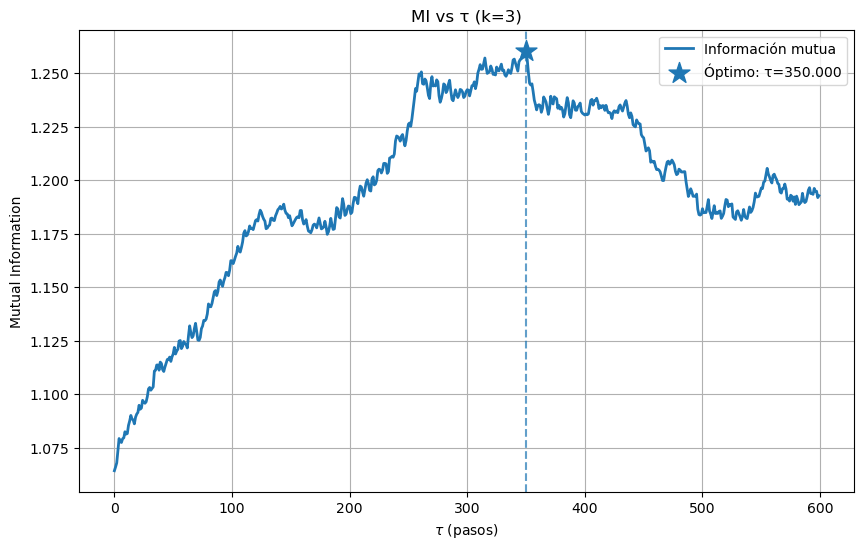

El desplazamiento óptimo para número de vecinos k=3 es: 350


Análisis de Tau: 100%|██████████| 600/600 [03:08<00:00,  3.19lag/s]


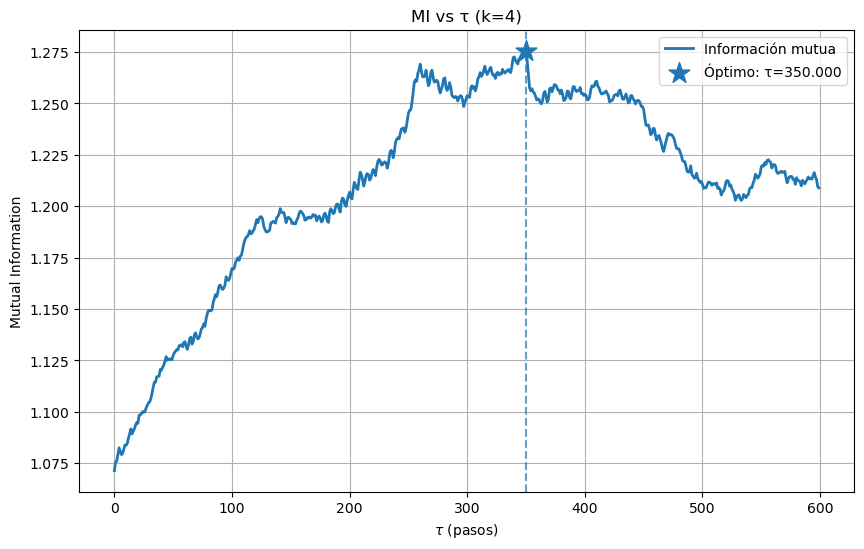

El desplazamiento óptimo para número de vecinos k=4 es: 350


Análisis de Tau: 100%|██████████| 600/600 [03:16<00:00,  3.06lag/s]


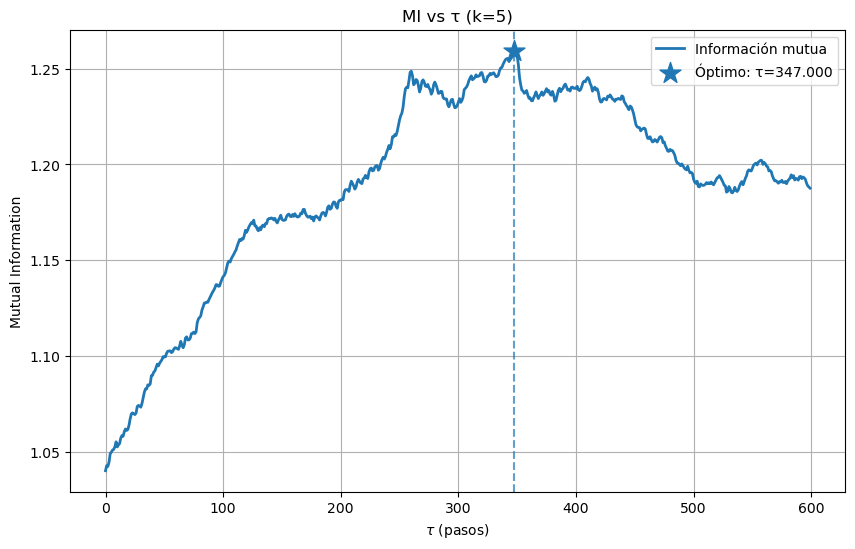

El desplazamiento óptimo para número de vecinos k=5 es: 347


Análisis de Tau: 100%|██████████| 600/600 [03:26<00:00,  2.91lag/s]


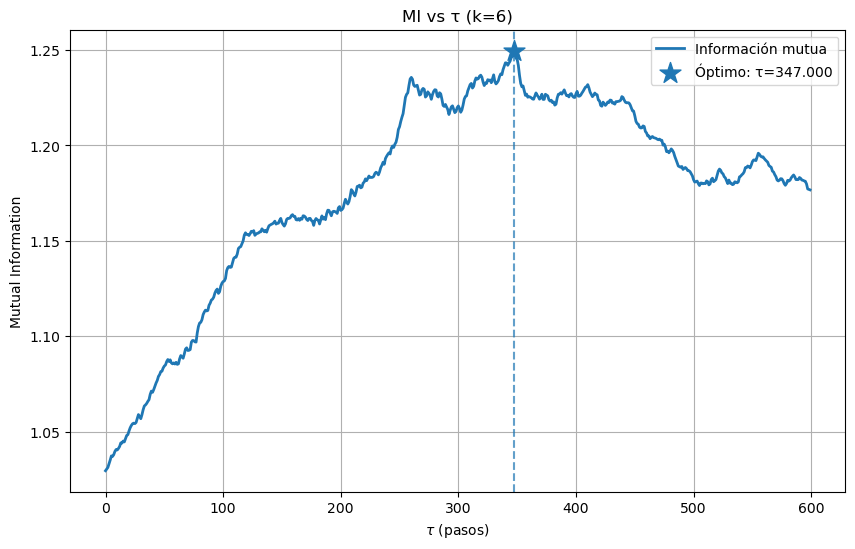

El desplazamiento óptimo para número de vecinos k=6 es: 347


Análisis de Tau: 100%|██████████| 600/600 [03:26<00:00,  2.90lag/s]


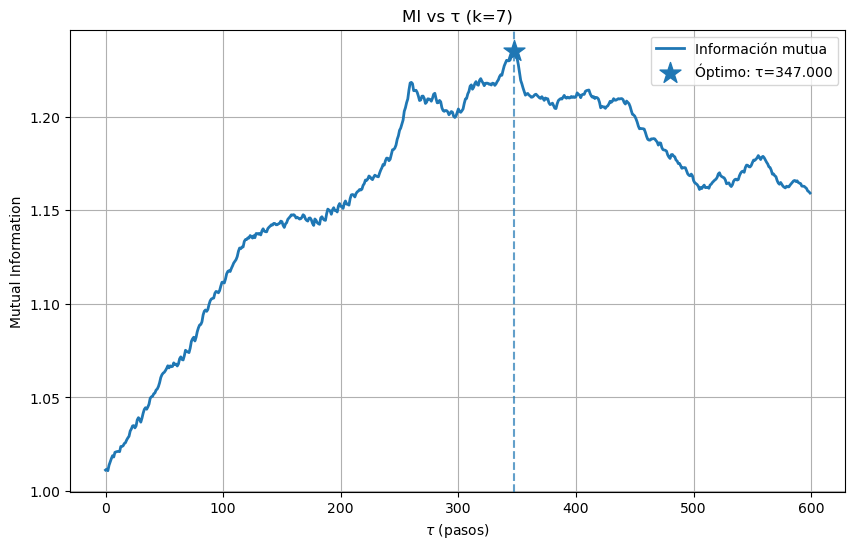

El desplazamiento óptimo para número de vecinos k=7 es: 347


In [16]:
vecinos_values = np.array([3,4,5,6,7])
for n_vecinos in vecinos_values:
    mis, best_tau = find_optimal_tau_MI(V1, V2, n_vecinos=n_vecinos, milisegundos = False, plot=True)
    
    print(f"El desplazamiento óptimo para número de vecinos k={n_vecinos} es: {best_tau}")

Se detecta una curva similar en todos los casos, independientemente del valor de `k` utilizado. En particular, para el valor `n_neighbors=4`, que resultó el óptimo en el análisis anterior, aparecen dos picos de intensidad muy similar en valor de delay $250$ y $350$. Con el objetivo de manetner coherencia con el estimador de TE que se desarrolla a continuación en este notebook, seleccionamos el valor de retardo: delay$=250$.


Calculando MI retardada para k = 1

Calculando MI retardada para k = 2

Calculando MI retardada para k = 3

Calculando MI retardada para k = 4

Calculando MI retardada para k = 5

Calculando MI retardada para k = 6

Calculando MI retardada para k = 7

Calculando MI retardada para k = 8

Calculando MI retardada para k = 9


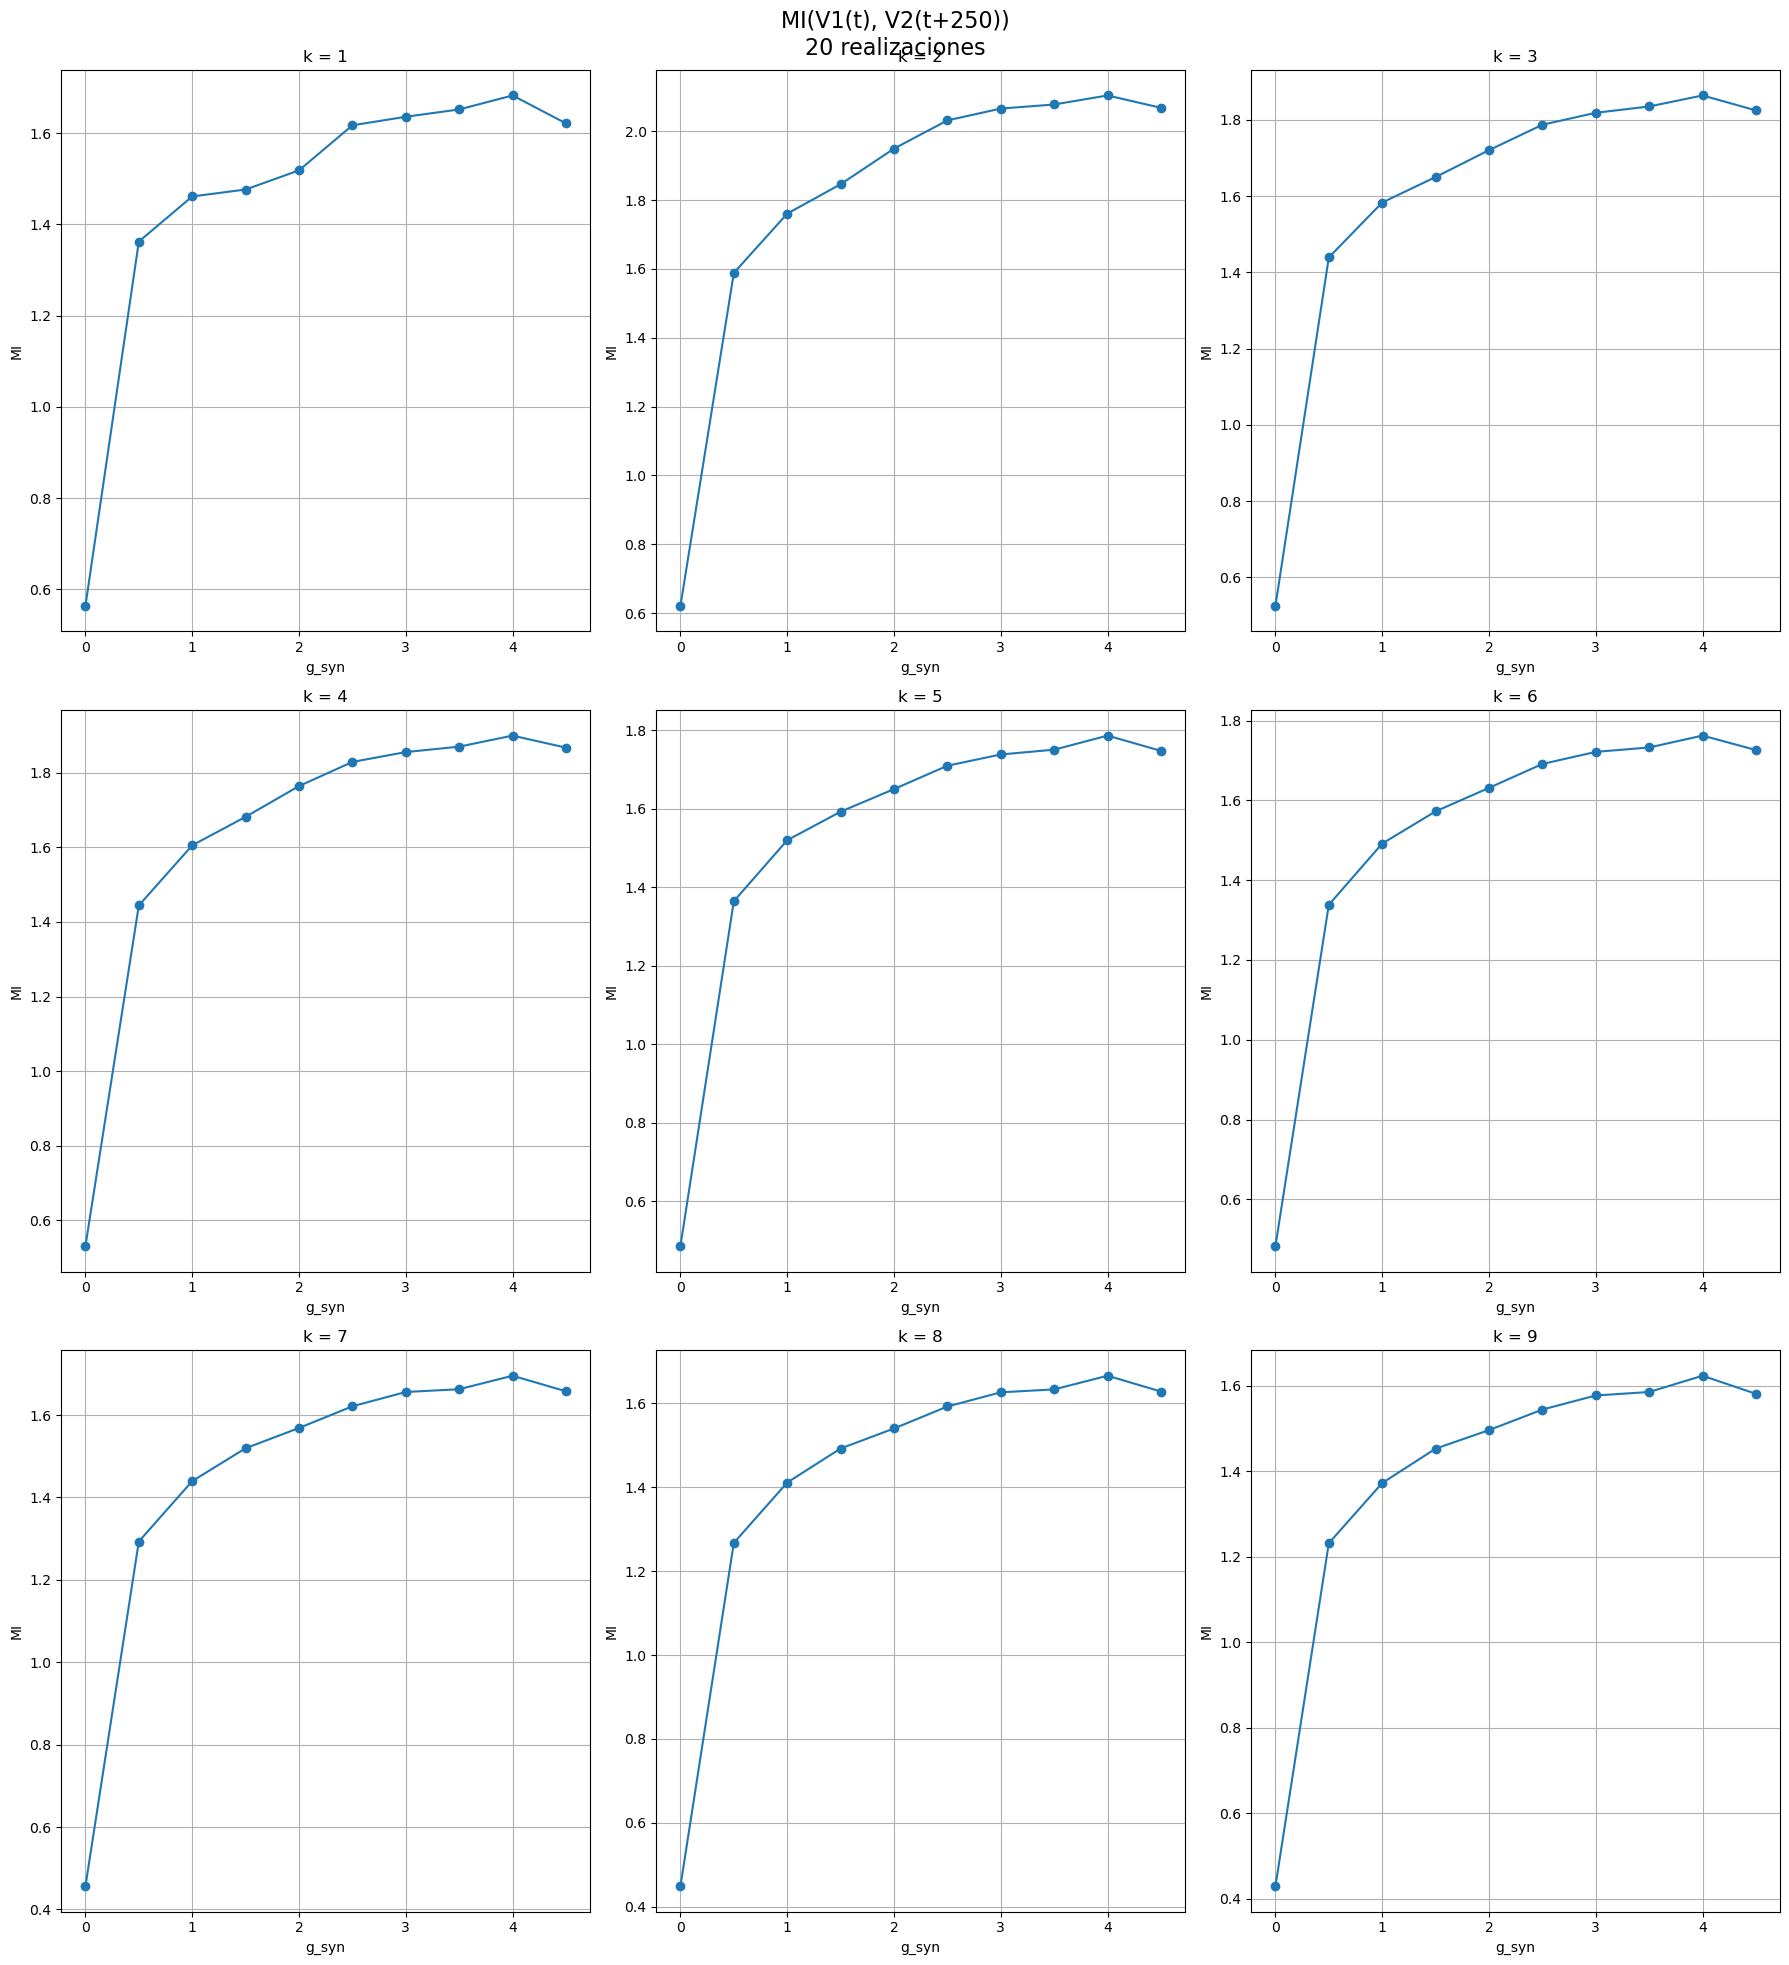

In [6]:
#factor = 5
n_runs = 20
lag = 250 

g_values = np.arange(0, 5, 0.5)
neighbors_list = np.arange(1, 10)

all_means_lag = []
all_std_lag = []

# Figura 5x3
fig, axes = plt.subplots(3, 3, figsize=(18, 20))
axes = axes.flatten()

for idx, k in enumerate(neighbors_list):

    print(f"\nCalculando MI retardada para k = {k}")

    mi_all = np.zeros((n_runs, len(g_values)))

    for run in range(n_runs):

        for j, g_syn in enumerate(g_values):

            V1, V2 = mn.hh_multirate(theta1=0.0, sigma1=0.0, theta2=0.0, sigma2=0.0, cte1=0.0, cte2=4.0, g_syn=g_syn, tau=0.0, std_e=0.03, std_i=0.006, ge0=0.05, gi0=0.006, use_OU_I1=False, use_OU_I2=False, plot=False)
            v1_fixed = V1[:-lag]
            v2_shifted = V2[lag:]
            v1_input = v1_fixed.reshape(-1, 1)
            v2_input = v2_shifted.ravel()

            mi = mutual_info_regression(v1_input, v2_input, n_neighbors=k, discrete_features=False)
            mi_all[run, j] = mi[0]

    # Estadísticos
    mi_mean = np.mean(mi_all, axis=0)
    mi_std = np.std(mi_all, axis=0)

    all_means_lag.append(mi_mean.copy())
    all_std_lag.append(mi_std.copy())

    upper_std = mi_mean + mi_std
    lower_std = mi_mean - mi_std

    # ======================
    # Plot
    # ======================
    ax = axes[idx]

    ax.plot(g_values, mi_mean, marker='o')
    ax.fill_between(g_values, lower_std, upper_std, alpha=0.3)

    ax.set_title(f"k = {k}")
    ax.set_xlabel("g_syn")
    ax.set_ylabel("MI")
    ax.grid(True)

plt.suptitle(
    f"MI(V1(t), V2(t+{lag}))\n"
    f"{n_runs} realizaciones",
    fontsize=16
)

plt.tight_layout()
plt.show()

Analizando los resultados anteriores, primeramente observamos una relativa independencia del hiperparámetro `n_neighbors` en el estimador de IM. Todos los valores analizados generan una curva ascendente de intensidad de IM según aumenta la fuerza del enlace (que modela `g_syn`). Ese comportamiento es el esperado (coherente estructuralmente). La forma de la curva es además similar en todos los casos. La única diferencia notable es la presencia de valores más altos cuuando el hiperparámetro `k` es pequeño. Las bandas de varianza no se distinguen en el dibujo dada la ínfima variabilidad de las repeticiones.

Con los datos de las anteriores gráficas, calculamos la media de la desviación estandar para cada valor de `k` (es decir agrupando valores de `g_syn`para cada valor fijo del parámetro `n_neighbors`).

Media de la std para cada k:
[3.55271368e-16 3.77475828e-16 4.88498131e-16 3.10862447e-16
 2.66453526e-16 5.10702591e-16 3.10862447e-16 3.77475828e-16
 4.66293670e-16]


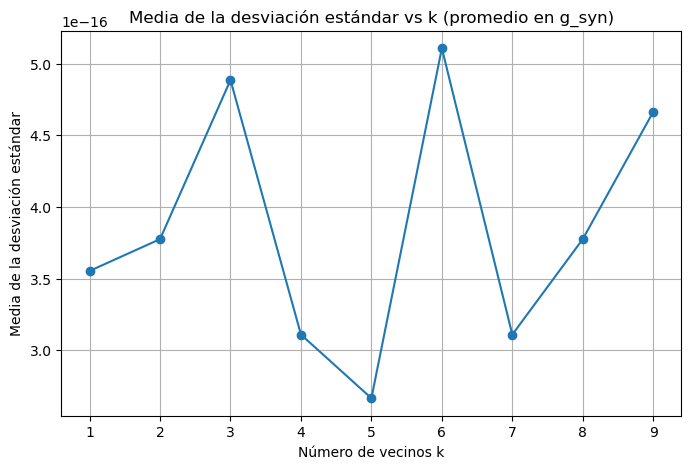

In [7]:
# Valores de k
k_values = np.arange(1, 10)

# Media para cada k
mean_std_per_k = np.array([np.mean(arr) for arr in all_std_lag])

print("Media de la std para cada k:")
print(mean_std_per_k)

# Plot
plt.figure(figsize=(8,5))
plt.plot(k_values, mean_std_per_k, marker='o')

plt.xlabel("Número de vecinos k")
plt.ylabel("Media de la desviación estándar")
plt.title("Media de la desviación estándar vs k (promedio en g_syn)")
plt.grid(True)


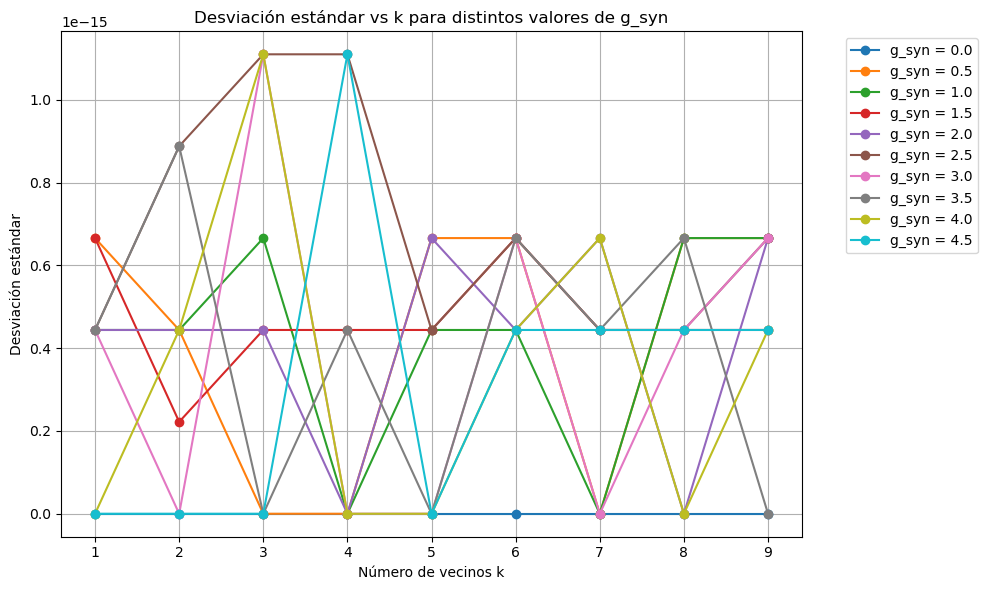

In [8]:
k_values = np.arange(1, 10)
g_values = np.arange(0, 5, 0.5)

all_std_array_lag = np.array(all_std_lag)

plt.figure(figsize=(10, 6))

for i, g_syn in enumerate(g_values):

    std_vs_k = all_std_array_lag[:, i]

    plt.plot(k_values, std_vs_k, marker='o', label=f"g_syn = {g_syn:.1f}")

plt.xlabel("Número de vecinos k")
plt.ylabel("Desviación estándar")
plt.title("Desviación estándar vs k para distintos valores de g_syn")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

La interpretabilidad de las anteriores gráficas es muy limitada debido a la escala de los resultados. Permiten reafirmar la robustez del estimador ante valores considerables del hiperparámetro. La variabilidad es prácticamente nula y la estimación aparentememnte coherente.

### Estimador de Transfer Entropy

A continuación se realiza un estudio estructuralmente análogo al anterior de la IM.

#### Modelo Teórico (Modelo VAR)

En este caso se usará un modelo lineal Autorregresivo como ground truth para los primeros análisis. 


Fijando un delay modelado mediante el parámetro $\tau$, se estudiará como varían las estimaciones de TE en función del número de vecinos `k`, cambiando el parámetro "b" del sistema que determina la intensidad del enlace entre las variables:
$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1} + \varepsilon_t^y 
\end{cases}
$$


Se fija $\tau=3$.

Para las primeras estimaciones teóricas se usa el estimador del valor teórico de la TE en modelos lineales gaussianos `GC_TE_autorreg_tau_gauss` (donde es igual a la GC) comentado en el Notebook "Igualdad entre GC y TE en modelos VAR". Esos valores servirán como referencia para evaluar el estimador de Transfer Entropy JIDT de Google Code.

In [3]:
def GC_TE_autorreg_tau_gauss(a, b, c, sig_x2, sig_y2, tau, datos=True):
    """
    Calcula la Granger Causality F y la Transfer Entropy TE
    usando las fórmulas analíticas derivadas del modelo VAR(1).
                  Y --> X
    """
    Vy = sig_y2 / (1 - c**2)   # Varianza de Y (Proceso AR(1) independiente)
    Cxy = (b * c**(tau-1) / (1 - a * c)) * Vy    # Covarianza X,Y 
    termino_intermedio = ((2 * a * b**2 * c**tau) / (1 - a * c)) + b**2
    Vx = (1 / (1 - a**2)) * (termino_intermedio * Vy + sig_x2)         # Varianza de X
    
    Var_Y_cond_X = Vy - (Cxy**2 / Vx)   # Var(Y | X) (para Gaussianas: Vy - (Cxy^2 / Vx))
    
    F = np.log((b**2 * Var_Y_cond_X + sig_x2) / sig_x2)    # Granger Causality: F = ln( Var_reducido / Var_completo )
    TE = 0.5 * F    # Transfer Entropy: TE = 1/2*F

    if datos:
        return {"Vx": Vx, "Vy": Vy, "Cxy": Cxy, "Var(Y|X)": Var_Y_cond_X, "Granger_F": F, "Transfer_Entropy": TE}
    else:
        return F, TE

Del mismo modo que ya se hizo, comenzamos analizando como se detecta la cantidad de TE según varía la intensidad de la unión (es decir `b`). Todo ello, a su vez, para diferentes valores del hiperparámetro `k=n_neighbors`.


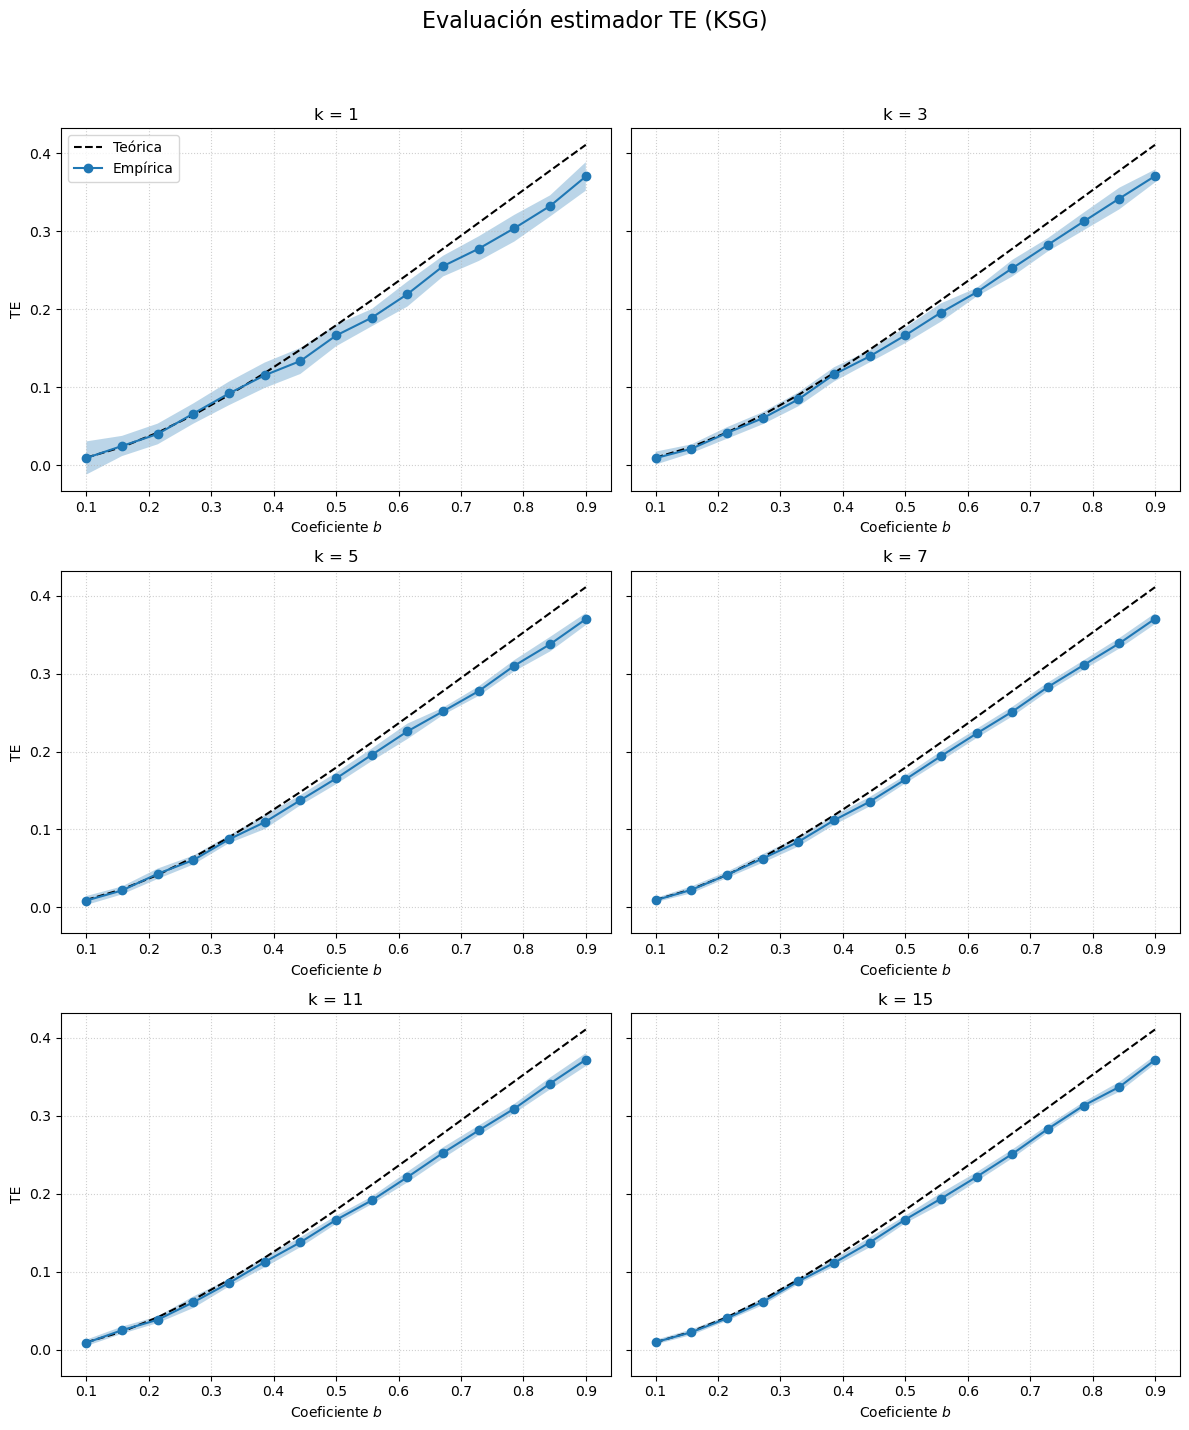

In [32]:
T = 10000
n_runs = 20

a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 3
b_values = np.linspace(0.1, 0.9, 15)


te_theo = np.zeros(len(b_values))
for j, b in enumerate(b_values): 
    # Te teórica
    _, te_theo[j] = GC_TE_autorreg_tau_gauss(a=a, b=b, c=c, sig_x2=sig_x2, sig_y2=sig_y2, tau=tau, datos=False)


fig, axes = plt.subplots(3, 2, figsize=(12, 15), sharey=True)
axes_flat = axes.flatten()

neighbors_list = [1, 3, 5, 7, 11, 15]

contexto_k = 1
contexto_l = 1
contexto_c = 1
hist = max(contexto_k, contexto_l, contexto_c)

for idx, n_neighbors in enumerate(neighbors_list):
    
    ax = axes_flat[idx]
    TE_emp_all = np.zeros((n_runs, len(b_values)))
    
    for j, b in enumerate(b_values):
        for run in range(n_runs):
            ex = np.random.normal(0, np.sqrt(sig_x2), T)
            ey = np.random.normal(0, np.sqrt(sig_y2), T)
            Z = np.zeros((T, 2))
            for t in range(tau, T):
                Z[t, 1] = c * Z[t-1, 1] + ey[t]
                Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]
            data = pd.DataFrame(Z, columns=['X', 'Y'])
            X = data['X'].values
            Y = data['Y'].values
            X = X[hist:]
            Y = Y[hist:]

            teCalc = TECalcClass()
            teCalc.setProperty("k", str(n_neighbors))
            teCalc.setProperty("k_HISTORY", str(contexto_k))
            teCalc.setProperty("l_HISTORY", str(contexto_l))   
            teCalc.setProperty("DELAY", str(tau))
            teCalc.initialise()
            teCalc.setObservations(Y.astype(np.float64), X.astype(np.float64))
            
            te_ksg_val = teCalc.computeAverageLocalOfObservations()
            TE_emp_all[run, j] = te_ksg_val

    TE_emp_mean = np.mean(TE_emp_all, axis=0)
    TE_emp_std  = np.std(TE_emp_all, axis=0)

    # Plot
    ax.plot(b_values, te_theo, 'k--', label="Teórica")
    ax.plot(b_values, TE_emp_mean, 'o-', label="Empírica")
    ax.fill_between(
        b_values,
        TE_emp_mean - TE_emp_std,
        TE_emp_mean + TE_emp_std,
        alpha=0.3
    )

    ax.set_title(f"k = {n_neighbors}")
    ax.set_xlabel(r"Coeficiente $b$")
    ax.grid(True, linestyle=':', alpha=0.6)

for i in range(3):
    axes[i, 0].set_ylabel("TE")

axes_flat[0].legend()

plt.suptitle("Evaluación estimador TE (KSG)", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Los resultados obtenidos admiten un anális idéntico al que se realizó en la IM. El sesgo del estimador aumenta y la varianza disminuye según `k` crece.
De nuevo, es interesante analizar el comportamiento para un valor $b = 0.5, 0.7$ fijos, en los que los valores de sesgo y varianza parecen más frágiles al valor del hiperparámetro `k`.

b = 0.5 -> k óptimo (MSE mínimo) = 3 | MSE min = 9.148540e-04
b = 0.7 -> k óptimo (MSE mínimo) = 6 | MSE min = 2.643253e-03


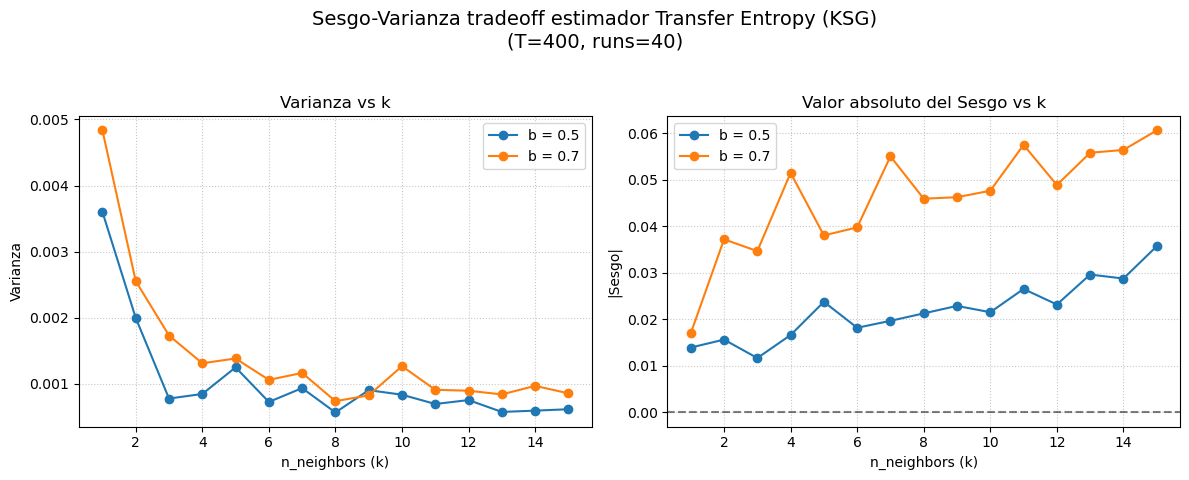

In [10]:
T = 400       
n_runs = 40     
a, c = 0.5, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 3
b_values = [0.5, 0.7]     
neighbors_list = np.arange(1, 16)

contexto_k = 1
contexto_l = 1
contexto_c = 1
hist = max(contexto_k, contexto_l, contexto_c)

results_by_b = {}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for b_fixed in b_values:

    var_k = []
    mean_k = []

    _, te_theo = GC_TE_autorreg_tau_gauss(a=a, b=b_fixed, c=c, sig_x2=sig_x2, sig_y2=sig_y2, tau=tau, datos=False)

    for n_neighbors in neighbors_list:
        te_runs = []
        
        for run in range(n_runs):
            ex = np.random.normal(0, np.sqrt(sig_x2), T)
            ey = np.random.normal(0, np.sqrt(sig_y2), T)
            X = np.zeros(T)
            Y = np.zeros(T)
            
            for t in range(1, T):
                Y[t] = c * Y[t-1] + ey[t]
            
            for t in range(tau, T):
                X[t] = a * X[t-1] + b_fixed * Y[t-tau] + ex[t]
            
            X = X[hist:]
            Y = Y[hist:]

            teCalc = TECalcClass()
            teCalc.setProperty("k", str(n_neighbors))
            teCalc.setProperty("k_HISTORY", str(contexto_k))
            teCalc.setProperty("l_HISTORY", str(contexto_l))   
            teCalc.setProperty("DELAY", str(tau))
            teCalc.initialise()
            teCalc.setObservations(Y.astype(np.float64), X.astype(np.float64))
            
            te_val = teCalc.computeAverageLocalOfObservations()
            te_runs.append(te_val)
        
        te_runs = np.array(te_runs)
        mean_k.append(np.mean(te_runs))
        var_k.append(np.var(te_runs))
        
    mean_k = np.array(mean_k)
    var_k = np.array(var_k)
    bias_k = mean_k - te_theo
    abs_bias_k = np.abs(bias_k)
    mse_k = var_k + bias_k**2
    k_opt = neighbors_list[np.argmin(mse_k)]

    results_by_b[b_fixed] = {
        "mean_k": mean_k,
        "var_k": var_k,
        "bias_k": bias_k,
        "abs_bias_k": abs_bias_k,
        "mse_k": mse_k,
        "k_opt": k_opt,
        "te_theo": te_theo,
    }

    print(f"b = {b_fixed} -> k óptimo (MSE mínimo) = {k_opt} | MSE min = {np.min(mse_k):.6e}")

    axes[0].plot(neighbors_list, var_k, "o-", label=f"b = {b_fixed}")
    axes[1].plot(neighbors_list, abs_bias_k, "o-", label=f"b = {b_fixed}")

axes[0].set_xlabel("n_neighbors (k)")
axes[0].set_ylabel("Varianza")
axes[0].set_title("Varianza vs k")
axes[0].grid(True, linestyle=":", alpha=0.7)
axes[0].legend()

axes[1].axhline(0, color="black", linestyle="--", alpha=0.5)
axes[1].set_xlabel("n_neighbors (k)")
axes[1].set_ylabel("|Sesgo|")
axes[1].set_title("Valor absoluto del Sesgo vs k")
axes[1].grid(True, linestyle=":", alpha=0.7)
axes[1].legend()

plt.suptitle(f"Sesgo-Varianza tradeoff estimador Transfer Entropy (KSG)\n(T={T}, runs={n_runs})", fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

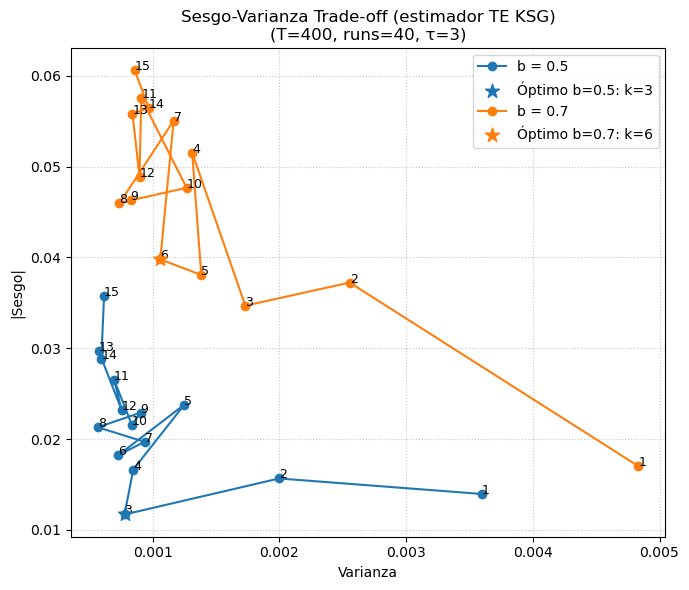

In [11]:
plt.figure(figsize=(7, 6))

for b_fixed, res in results_by_b.items():
    var_k = res["var_k"]
    abs_bias_k = res["abs_bias_k"]
    mse_k = res["mse_k"]
    k_opt = res["k_opt"]
    idx_opt = np.argmin(mse_k)

    plt.plot(var_k, abs_bias_k, "o-", label=f"b = {b_fixed}")
    for i, k in enumerate(neighbors_list):
        plt.text(var_k[i], abs_bias_k[i], str(k), fontsize=9)
    plt.scatter(
        var_k[idx_opt],
        abs_bias_k[idx_opt],
        s=110,
        marker="*",
        zorder=5,
        label=f"Óptimo b={b_fixed}: k={k_opt}",
    )

plt.xlabel("Varianza")
plt.ylabel("|Sesgo|")
plt.title(f"Sesgo-Varianza Trade-off (estimador TE KSG)\n(T={T}, runs={n_runs}, τ={tau})")
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Los resultados son de nuevo los esperados. El valor de la varianza de las estiamciones disminuye según `k` aumenta, al contrario que el valor del sesgo que es mayor para valores altos del hiperparámetro. De nuevo, parece que los valores óptimos del hiperparámetro se encuentran entre $3$ y $6$.

#### Modelo Práctico (Simulación 2 neuronas)

En este caso sí se utilizará el mismo modelo de simulación que en la IM para realizar el análisis desde una perspetiva más real.

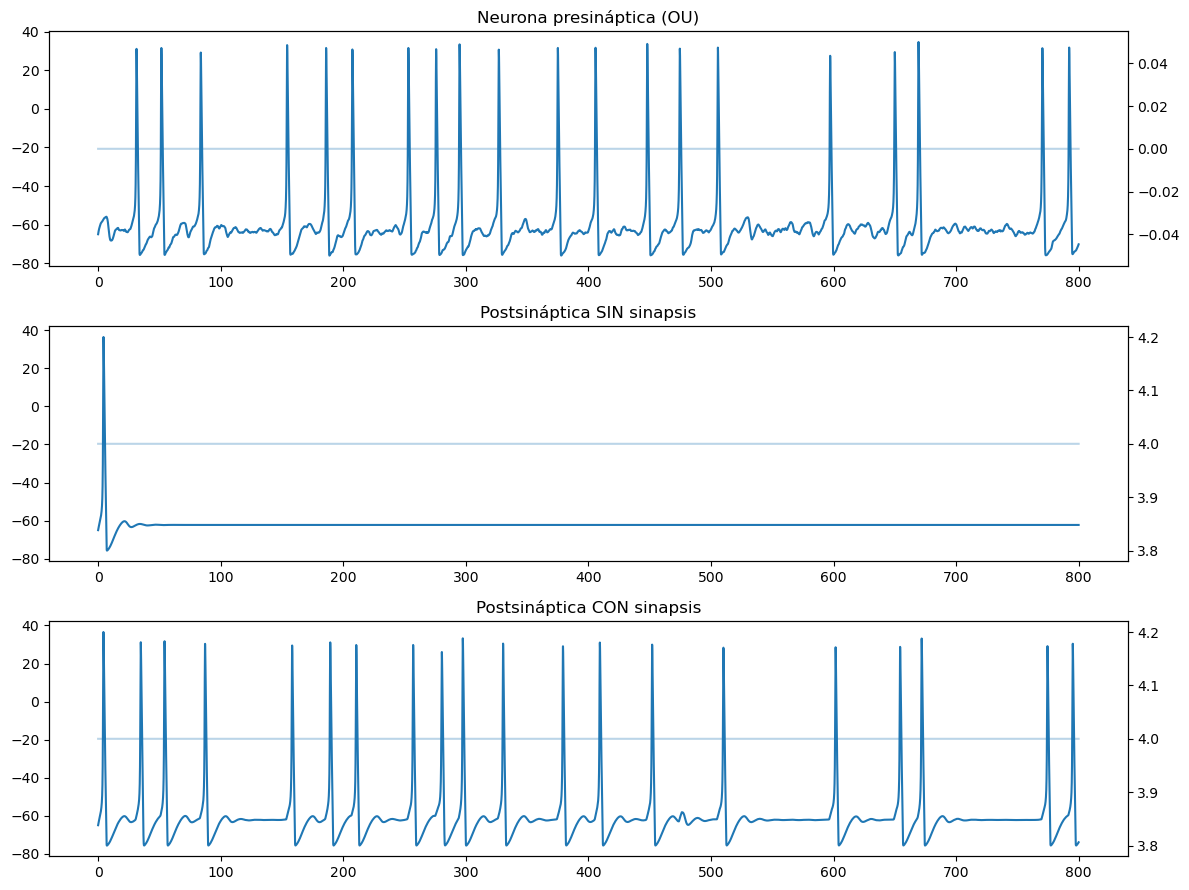

In [17]:
g_syn = 2.5
tau = 0.0    #tau = 1.0 --> 0.1 segundos --> 100 ms

# TE 2. Simulación sin ruido (activación de la neurona 1 con sinapsis del entorno)
V1, V2 = mn.hh_multirate(T=800, theta1=0.0, sigma1=0.0, theta2=0.0, sigma2=0.0, cte1=0.0, cte2=4.0, g_syn=g_syn, tau=tau, std_e=0.03, std_i=0.006, ge0=0.05, gi0=0.006, use_OU_I1=False, use_OU_I2=False, plot=True)

De nuevo, comenzamos evaluando el retardo causal del modelo sintético para realizar las estiamciones de TE de manera óptima.

In [6]:
def find_optimal_tau_TE_JIDT(V1, V2, n_vecinos, max_steps=600, contexto_k=5, contexto_l=5, contexto_c=50, factor_bool=True, plot=False, inverse=False, conditional=False, padres_source=None):
    """
    Calcula la Transfer Entropy (TE) para distintos valores de tau_source con el código de JIDT.
    Si inverse=True:
        calcula también V2 -> V1.
    Si conditional=True:
        calcula también la CTE V1 -> V2 | V2
    Retorna:
        tau_values, te_direct, optimal_tau

    """
    tau_values = np.arange(1, max_steps + 1)
    te_results = []

    if inverse:
        te_inverse_results = []
        
    if conditional:
        cte_results = []
    
    factor = 5   

    if factor_bool:
        V1 = V1[::factor]
        V2 = V2[::factor]

    hist = max(contexto_k, contexto_l, contexto_c)
    V1 = V1[hist:]
    V2 = V2[hist:]

        
        # --- TE Directa (V1 -> V2) ---
    teCalc = TECalcClass()
    teCalc.setProperty("k", str(n_vecinos))
    teCalc.setProperty("k_HISTORY", str(contexto_k))
    teCalc.setProperty("l_HISTORY", str(contexto_l))
    

    for tau in tqdm(tau_values, desc="Análisis de Tau", unit="tau"):
        
        teCalc.setProperty("DELAY", str(tau))
        teCalc.initialise()
        teCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64))
        te = teCalc.computeAverageLocalOfObservations()
        te_results.append(te)

         # --- TE Inversa (V2 -> V1) ---
    if inverse:
    
            teCalc_inv = TECalcClass()
            teCalc_inv.setProperty("k", str(n_vecinos))
            teCalc_inv.setProperty("k_HISTORY", str(contexto_k))
            teCalc_inv.setProperty("l_HISTORY", str(contexto_l))
    
            for tau in tqdm(tau_values, desc="TE V2 → V1", unit="tau"):
                teCalc_inv.setProperty("DELAY", str(tau))
                teCalc_inv.initialise()
                teCalc_inv.setObservations(V2.astype(np.float64),V1.astype(np.float64))
                te_inv = teCalc_inv.computeAverageLocalOfObservations()
                te_inverse_results.append(te_inv)
                

        # --- CTE (V1 -> V2 | V2) ---
    if conditional:
        cteCalc = CTEClass() 
        cteCalc.setProperty("k", str(n_vecinos))
        cteCalc.setProperty("k_HISTORY", str(contexto_k))
        cteCalc.setProperty("l_HISTORY", str(contexto_l))
        cteCalc.setProperty("c_HISTORY", str(contexto_c))
    
        for tau in tqdm(tau_values, desc="CTE V1 → V2 | V2", unit="tau"):
            cteCalc.setProperty("DELAY", str(tau))
            cteCalc.initialise()
            cteCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64), V2.astype(np.float64))
            cte_val = cteCalc.computeAverageLocalOfObservations()
            cte_results.append(cte_val)


    te_results = np.array(te_results)
    if inverse:
        te_inverse_results = np.array(te_inverse_results)
    if conditional:
        cte_results = np.array(cte_results)

    optimal_idx = np.argmax(te_results)
    optimal_tau = tau_values[optimal_idx]
    
    if factor_bool:
        optimal_tau = optimal_tau * factor
        tau_values = tau_values * factor

    # Gráfica
    if plot:

        plt.figure(figsize=(10, 6))
        plt.plot(tau_values, te_results, lw=2, label="Transfer Entropy (Direct)")
        if padres_source is not None:
            if np.isscalar(padres_source):
                padres_source = [padres_source]
            for i, delay in enumerate(padres_source):
                if delay in tau_values:
                    idx = np.where(tau_values == delay)[0][0]
                    plt.scatter(tau_values[idx], te_results[idx], marker="*", s=250, zorder=5, label="Padre seleccionado" if i == 0 else None)
        if inverse:
            plt.plot(tau_values, te_inverse_results, color="gray", alpha=0.45, lw=1.8, linestyle="--", label="TE V2 → V1")
        if conditional:
            plt.plot(tau_values, cte_results, color="red", alpha=0.35, lw=1.8, linestyle="--", label="CTE V1 → V2 | V2")
        plt.axvline(tau_values[optimal_idx], linestyle="--", alpha=0.7)
        plt.xlabel("Delay")
        plt.ylabel("Transfer Entropy")
        plt.title(f"TE (JIDT-Kraskov) vs Delay "f"(k={n_vecinos})")
        plt.grid(True)
        plt.legend()
        plt.show()


    return tau_values, te_results, optimal_tau

Análisis de Tau: 100%|██████████| 350/350 [41:13<00:00,  7.07s/tau]


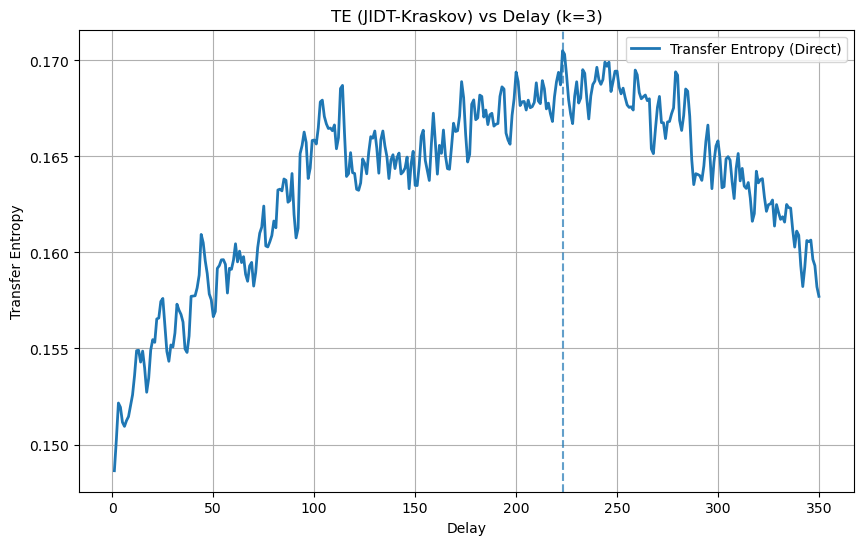

El delay óptimo para k=3 es: 223.000 ms


Análisis de Tau: 100%|██████████| 350/350 [28:08<00:00,  4.82s/tau]


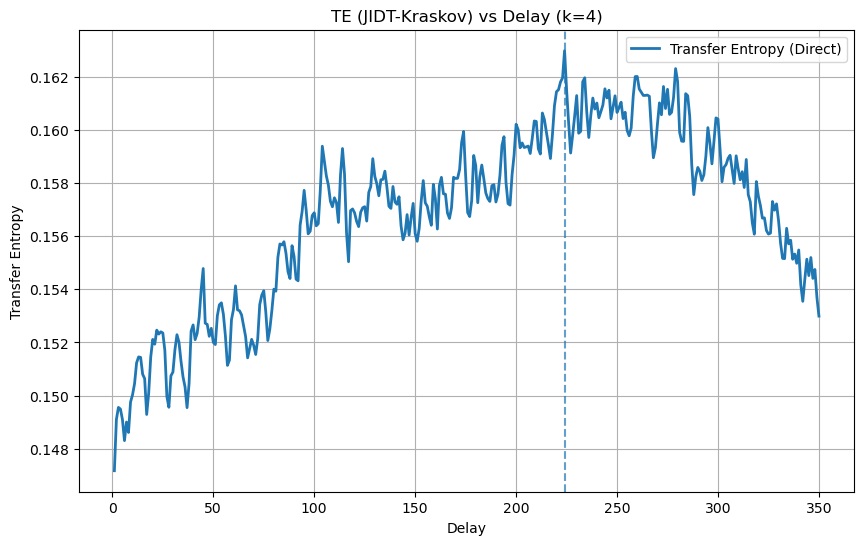

El delay óptimo para k=4 es: 224.000 ms


Análisis de Tau: 100%|██████████| 350/350 [26:29<00:00,  4.54s/tau]


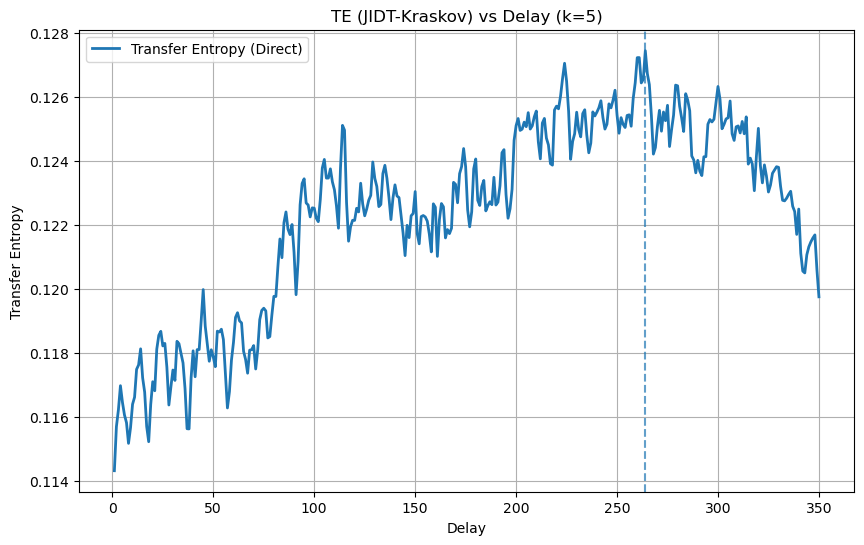

El delay óptimo para k=5 es: 264.000 ms


Análisis de Tau: 100%|██████████| 350/350 [26:06<00:00,  4.47s/tau]


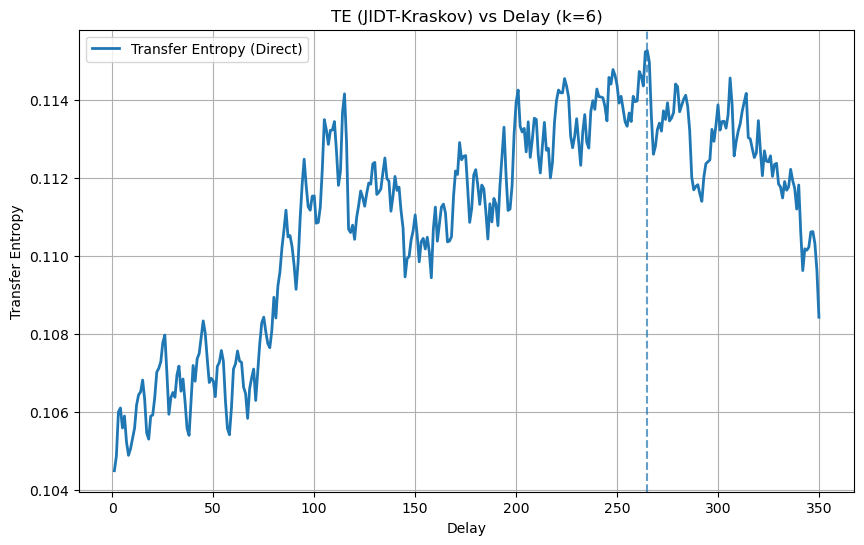

El delay óptimo para k=6 es: 265.000 ms


Análisis de Tau: 100%|██████████| 350/350 [25:40<00:00,  4.40s/tau]


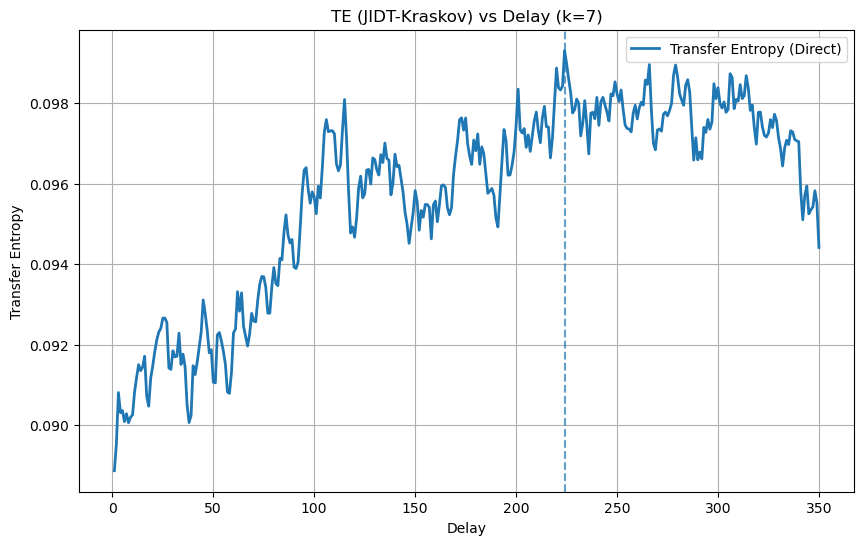

El delay óptimo para k=7 es: 224.000 ms


In [65]:
vecinos_values = np.array([3,4,5,6,7])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(V1, V2, n_vecinos=n_vecinos, max_steps=350, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

Las anteriores estimaciones son más sensibles al valor de `k` seleccionado, a diferencia de lo que ocurría en el estimador de IM. Aparentemente el estimador de TE es más dependiente del valor de hiperparámetro. Se seleccionará el valor de retardo $\tau = 224$ para los análisis.

A continuación la estimación de TE en función de la intensidad de unión (modelada mediante `g_syn`), para diferentes valores del hiperparámetro `k=n_neighbors`, midiendo la varianza entre diferentes realizaciones.


Calculando TE para k = 1

Calculando TE para k = 2

Calculando TE para k = 3

Calculando TE para k = 4

Calculando TE para k = 5

Calculando TE para k = 6

Calculando TE para k = 7

Calculando TE para k = 8

Calculando TE para k = 9


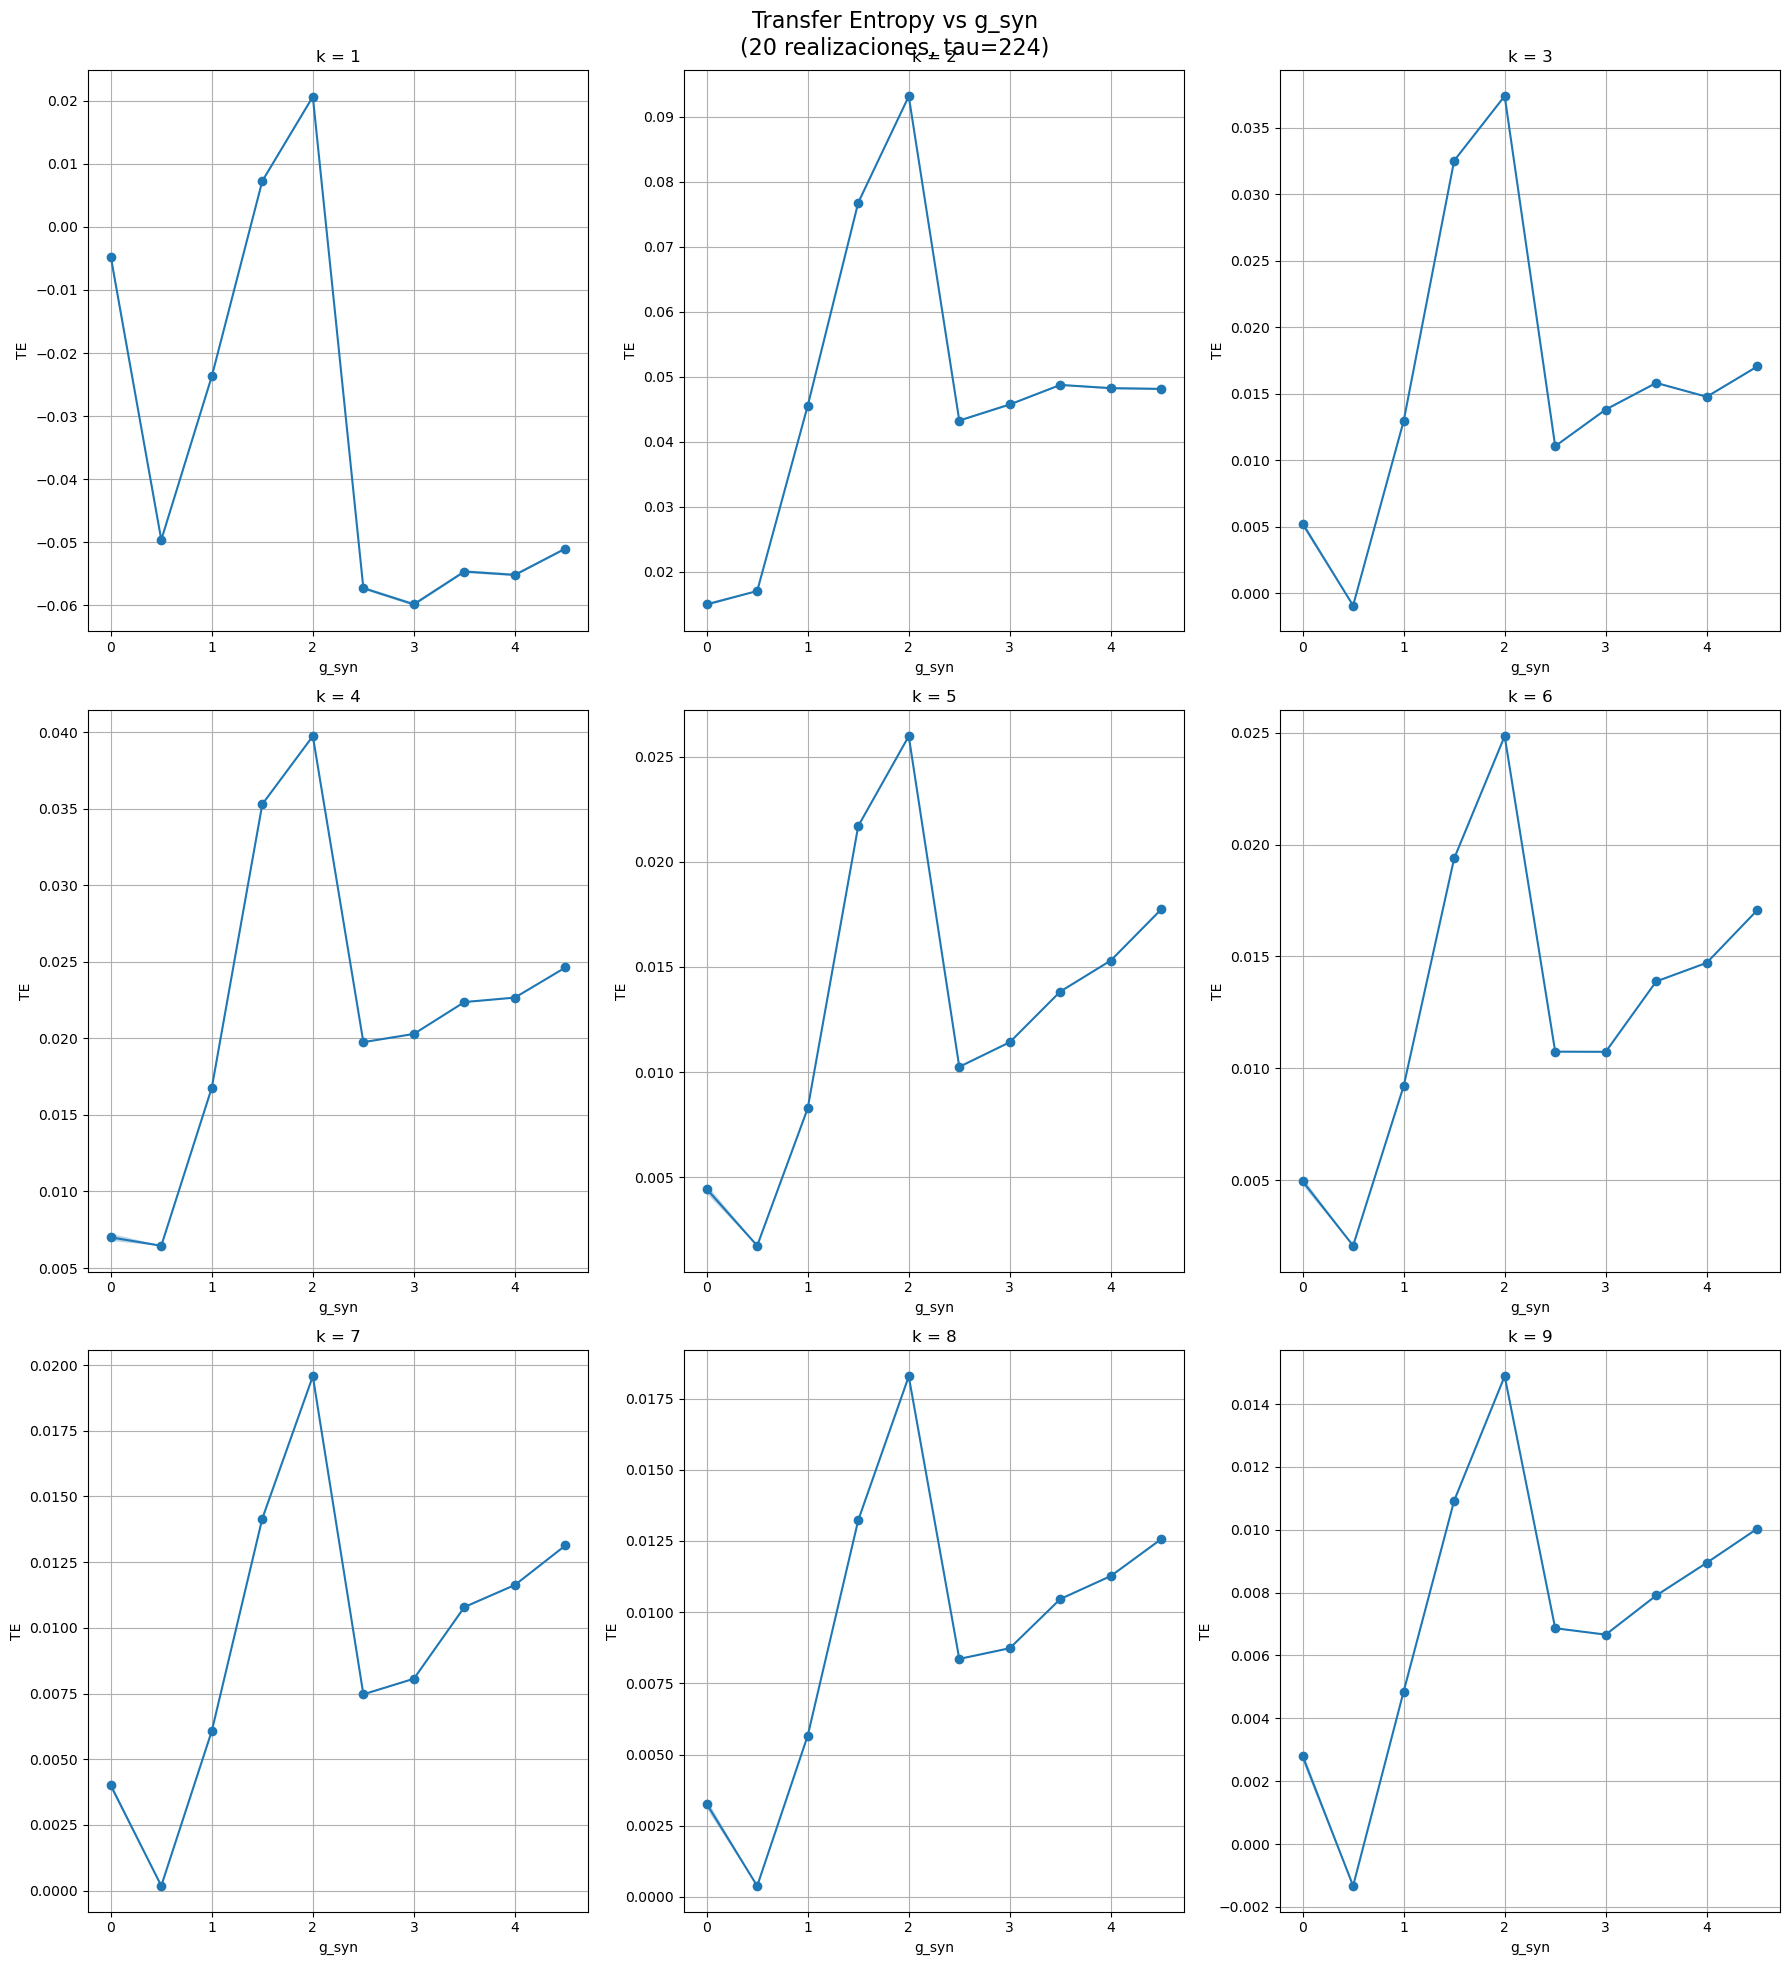

In [7]:
#factor = 5
n_runs = 20
tau = 224

g_values = np.arange(0, 5, 0.5)
neighbors_list = np.arange(1, 10)

te_all_mean_tau = []
te_all_std_tau = []

contexto_k = 1
contexto_l = 1
contexto_c = 1
hist = max(contexto_k, contexto_l, contexto_c)

# Figura 5x3
fig, axes = plt.subplots(3, 3, figsize=(18, 20))
axes = axes.flatten()

for idx, n_neighbors in enumerate(neighbors_list):

    print(f"\nCalculando TE para k = {n_neighbors}")

    te_all = np.zeros((n_runs, len(g_values)))
    for run in range(n_runs):

        for j, g_syn in enumerate(g_values):

            V1, V2 = mn.hh_multirate(theta1=0.0, sigma1=0.0, theta2=0.0, sigma2=0.0, cte1=0.0, cte2=4.0, g_syn=g_syn, tau=tau, std_e=0.03, std_i=0.006, ge0=0.05, gi0=0.006, use_OU_I1=False, use_OU_I2=False, plot=False)
            V1 = V1[hist:]
            V2 = V2[hist:]
            #v1_input = V1[::factor]
            #v2_input = V2[::factor]

            teCalc = TECalcClass()
            teCalc.setProperty("k", str(n_neighbors))
            teCalc.setProperty("k_HISTORY", str(contexto_k))
            teCalc.setProperty("l_HISTORY", str(contexto_l))   
            teCalc.setProperty("DELAY", str(tau))
            teCalc.initialise()
            teCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64))
            
            te = teCalc.computeAverageLocalOfObservations()
            te_all[run, j] = te

    # Estadísticos
    te_mean = np.mean(te_all, axis=0)
    te_std = np.std(te_all, axis=0)

    te_all_mean_tau.append(te_mean.copy())
    te_all_std_tau.append(te_std.copy())

    upper_std = te_mean + te_std
    lower_std = te_mean - te_std

    ax = axes[idx]

    ax.plot(g_values, te_mean, marker='o', label="Media TE")

    ax.fill_between(g_values, lower_std, upper_std, alpha=0.3, label="± std")

    ax.set_title(f"k = {n_neighbors}")
    ax.set_xlabel("g_syn")
    ax.set_ylabel("TE")
    ax.grid(True)

plt.suptitle(
    f"Transfer Entropy vs g_syn\n"
    f"({n_runs} realizaciones, tau={tau})",
    fontsize=16
)

plt.tight_layout()
plt.show()

De nuevo, la principal diferencia del resultado, obtenido para diferentes valores del hiperparámetro, es la tendencia descendente en la intensidad en términos generales según el valor de `k` es más grande. Pero en este caso se observa un interesante comportamiento de la TE: un primer asceno con g_syn hasta llegar a un pico y luego descenso de la TE. A partir de g_syn igual a $2.0$ la TE disminuye porque V2 se vuelve esclava de V1, ambos potenciales se sincronizan. Desde un punto de vista teórico, la Transfer Entropy cuantifica la reducción de la incertidumbre en la predicción del estado futuro de la neurona receptora ($V_2$) al incorporar el pasado de la neurona impulsora ($V_1$), condicionada a la propia historia de $V_2$. Para valores moderados de $g_{syn}$, el acoplamiento incrementa la dependencia causal efectiva, elevando la TE hasta un máximo. Sin embargo, cuando la conductancia supera el umbral crítico ($g_{syn} \ge 2.0 - 2.5$), el sistema transita hacia un régimen de sincronización estricta. En este estado de fuerte sincronía determinista, la dinámica de $V_2$ queda completamente dictada por la trayectoria de $V_1$, colapsando el espacio de fases sobre una variedad sincronizada de menor dimensión. Al extinguirse la variabilidad estocástica y volverse las series casi redundantes, la incertidumbre se desvanece de forma simétrica en el estimador, lo que provoca un desplome matemático de la TE a pesar de que la influencia física de acoplamiento es máxima.


A continuación se hace visible gráficamente el fenómeno que sucede en el salto de g_syn=2.0 a g_syn=2.5. Mientras que en el primer caso (g_syn=2.0), la segunda neurona todavía preserva cierta independencia, en el segundo caso (g_syn=2.5) la secuencia de disparos presenta una equivalencia exacta con la de la primera neurona, con el desfase concreto que ya se detectó. La intensidad del flujo de información es tan fuerte que la segunda neurona es esclava de la primera y el estimador deja de capturar transferencia efectiva de información; al dejar de existir novedad estadística o grados de libertad independientes entre las señales, el sistema se comporta internamente como una única unidad determinista, anulando el flujo de información medible y evidenciando una limitación fundamental de las métricas informacionales en regímenes de sincronización fuerte.

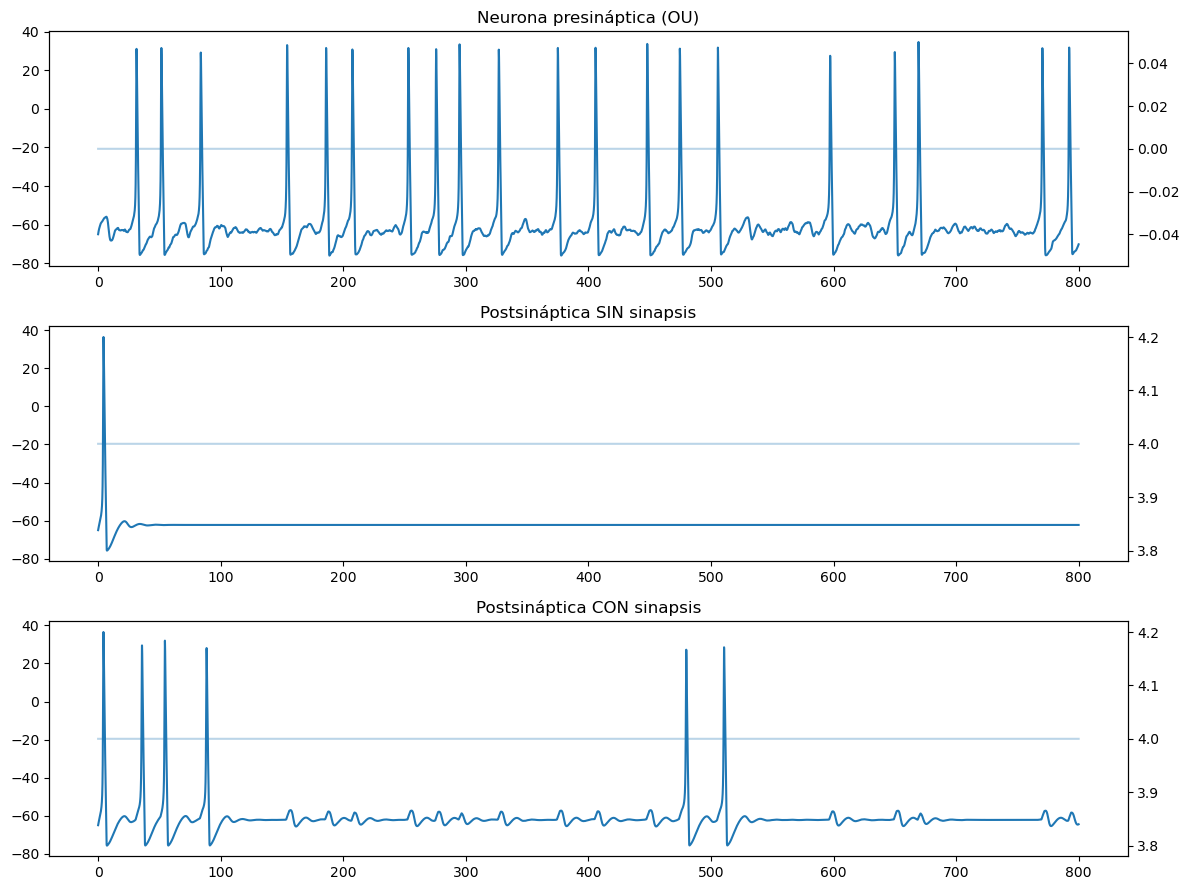

In [10]:
g_syn = 2.0
tau = 0.0    #tau = 1.0 --> 0.1 segundos --> 100 ms

# TE 2. Simulación sin ruido (activación de la neurona 1 con sinapsis del entorno)
V1, V2 = mn.hh_multirate(T=800, theta1=0.0, sigma1=0.0, theta2=0.0, sigma2=0.0, cte1=0.0, cte2=4.0, g_syn=g_syn, tau=tau, std_e=0.03, std_i=0.006, ge0=0.05, gi0=0.006, use_OU_I1=False, use_OU_I2=False, plot=True)

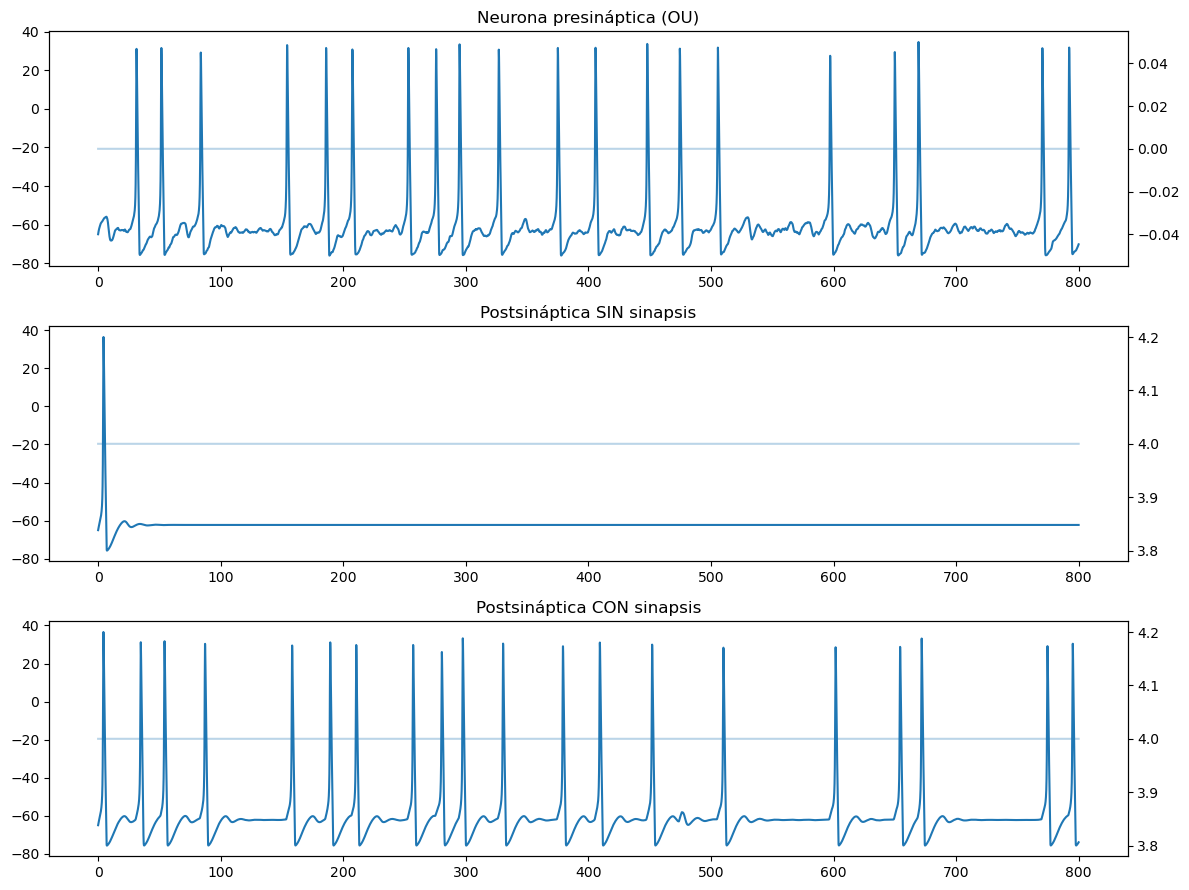

In [12]:
g_syn = 2.5
tau = 0.0    #tau = 1.0 --> 0.1 segundos --> 100 ms

# TE 2. Simulación sin ruido (activación de la neurona 1 con sinapsis del entorno)
V1, V2 = mn.hh_multirate(T=800, theta1=0.0, sigma1=0.0, theta2=0.0, sigma2=0.0, cte1=0.0, cte2=4.0, g_syn=g_syn, tau=tau, std_e=0.03, std_i=0.006, ge0=0.05, gi0=0.006, use_OU_I1=False, use_OU_I2=False, plot=True)

Con los datos de las anteriores gráficas, calculamos la media de desiación estandar para cada valor de `k`. La banda de desviación estandar no se ve en el dibujo porque sus valores son muy pequeños.

Media de la std para cada k:
[2.33547164e-04 1.34044554e-04 6.70640445e-05 5.21548124e-05
 4.58489727e-05 3.70378892e-05 3.05123152e-05 3.41899667e-05
 2.97584625e-05]


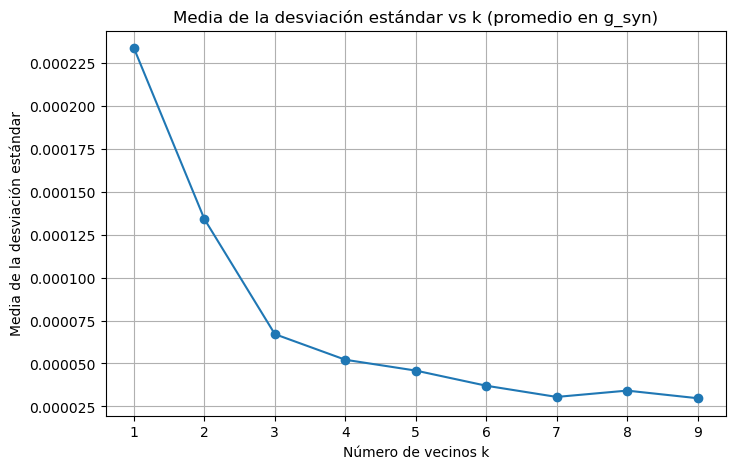

In [8]:
# Valores de k
k_values = np.arange(1, 10)

# Media para cada k
mean_std_per_k = np.array([np.mean(arr) for arr in te_all_std_tau])

print("Media de la std para cada k:")
print(mean_std_per_k)

# Plot
plt.figure(figsize=(8,5))
plt.plot(k_values, mean_std_per_k, marker='o')

plt.xlabel("Número de vecinos k")
plt.ylabel("Media de la desviación estándar")
plt.title("Media de la desviación estándar vs k (promedio en g_syn)")
plt.grid(True)

En este caso la escala de los valores de varianza no es despreciable (como sí ocurría con el estimador de IM), siendo aún suficientemente pequeños como para afirmar que el estimador es robusto independientemente del valor de `n_neighbors`. Sin embargo, en este caso si recuperamos la tendencia decreciente de variabilidad según aumenta el vecinadrio del estimador KSG. Dada a su vez la tendencia de aumento de sesgo detectada anteriormente en el 'caso teórico' utilizado como ground truth, se puede inferir que valores `n_neighbors`$=3,4$ podrían ser óptimos al ser el punto donde cambia la curvatura de la varianza (puntos del codo de la gráfica). Es decir, los valores `n_neighbors`$=3,4$ aportan un fuerte descenso de la varinaza al estimador, y además se infiere por la intuición creada con el estudio ground truth que son valores de estimación acordes a la realidad (sin dejar ascender el sesgo). 

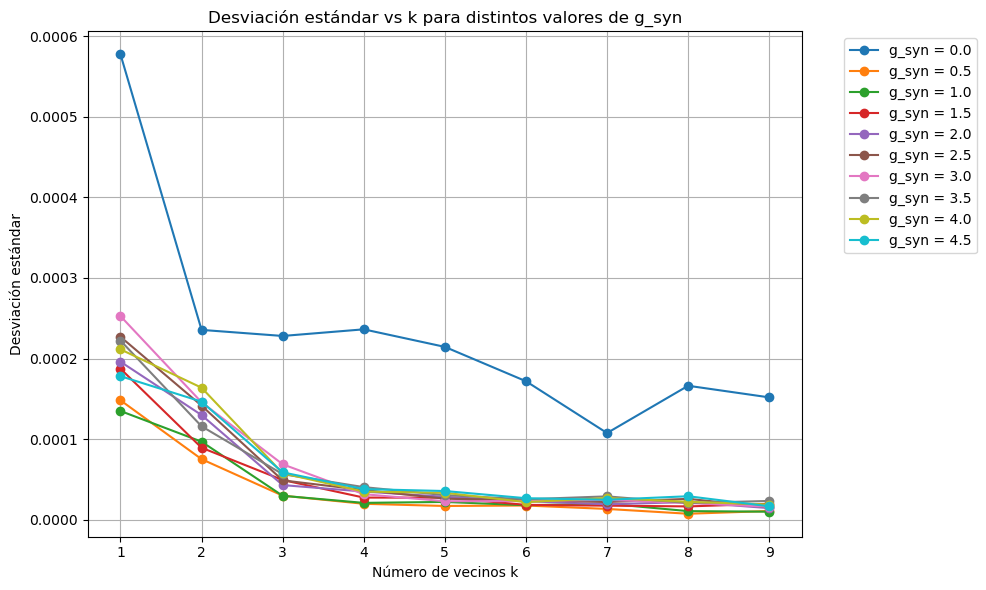

In [9]:
k_values = np.arange(1, 10)
g_values = np.arange(0, 5, 0.5)

all_std_array = np.array(te_all_std_tau)

plt.figure(figsize=(10, 6))

for i, g_syn in enumerate(g_values):

    std_vs_k = all_std_array[:, i]

    plt.plot(k_values, std_vs_k, marker='o', label=f"g_syn = {g_syn:.1f}")

plt.xlabel("Número de vecinos k")
plt.ylabel("Desviación estándar")
plt.title("Desviación estándar vs k para distintos valores de g_syn")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Conclusión: 

- la TE depende mucho más del parámetro k que la Información Mutua.
- en cuanto al tradeoff entre varianza y sesgo, concluimos dados los anteriores experimentos que valores del hiperparámetro `n_neighbors` entre $3$ y $5$ son fiables para el estimador KSG. En este trabajo se utilizará `n_neighbors`$=4$.